# Results analysis: the effect of inter-agent trust on LLM-Debate resilience

This notebook contains my attempt at analysing the data generated by LLM-Debate over the course of the thesis experiment. I focus on one question: **does message-level trust allocation make LLM-Debate more resilient to errors and simulated AiTM-style message manipulation?**

The Data contains two configurations:

- **Gemma:** Gemma 4 31B runs the debate agents, trust allocator and injector.
- **Qwen:** Qwen 3.5 9B runs the debate agents; Qwen 3.8 27B runs the trust allocator and injector.

Each task appears in four conditions: clean without trust (`baseline_off`), clean with trust (`baseline_on`), injected without trust (`fork_off`) and injected with trust (`fork_on`).

To run this notebook, upload the data files as compressed rar archives. Dataset can be found at [link]. Tables and figures are saved in  `results_outputs/` for future use.

## 1. Load the experiment results

I first extract the two RAR archives. If they are already extracted, this cell skips extraction. In Colab, I upload both archives to `/content` before running it.

In [2]:
from pathlib import Path
import shutil
import subprocess

RESULTS_ROOT = Path("/content/results")
EXPECTED_RUNS = [
    "agents-gemma4-31b__trust-gemma4-31b",
    "agents-qwen3.5-9b__trust-qwen3.8-27b_recovered",
]

summaries_present = all(
    (RESULTS_ROOT / run_name / "summary.csv").exists()
    for run_name in EXPECTED_RUNS
)

if not summaries_present:
    if shutil.which("unrar") is None:
        subprocess.run(
            ["bash", "-lc", "apt-get update -qq && apt-get install -y -qq unrar"],
            check=True,
        )

    gemma_archives = sorted(Path("/content").glob("agents-gemma*.rar"))
    qwen_archives = sorted(Path("/content").glob("agents-qwen*.rar"))

    if not gemma_archives or not qwen_archives:
        raise FileNotFoundError(
            "I could not find both RAR archives in /content. "
            "Upload the Gemma and Qwen archives, then rerun this cell."
        )

    RESULTS_ROOT.mkdir(parents=True, exist_ok=True)

    for archive in [gemma_archives[0], qwen_archives[0]]:
        print(f"Extracting {archive.name}")
        # Use 'unrar x' to extract with full paths, and '-o+' to overwrite existing files
        subprocess.run(
            ["unrar", "x", "-o+", str(archive), str(RESULTS_ROOT) + "/"],
            check=True,
            capture_output=True,
            text=True,
        )
else:
    print("Both experiment folders are already extracted. I will reuse them.")

for run_name in EXPECTED_RUNS:
    summary_path = RESULTS_ROOT / run_name / "summary.csv"
    print(run_name, "->", summary_path.exists())

Extracting agents-gemma4-31b__trust-gemma4-31b.rar
Extracting agents-qwen3.5-9b__trust-qwen3.8-27b_recovered.rar
agents-gemma4-31b__trust-gemma4-31b -> True
agents-qwen3.5-9b__trust-qwen3.8-27b_recovered -> True


I now load the summary files and the libraries used for the analysis. I use Seaborn for every figure and keep the same colours throughout: blue for Gemma and orange for Qwen.

In [3]:
import json
import re
import hashlib
import warnings
from collections import defaultdict

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from scipy.stats import binomtest, wilcoxon
from sklearn.metrics import roc_auc_score, roc_curve
from statsmodels.stats.proportion import proportion_confint
from statsmodels.stats.multitest import multipletests

sns.set_theme(
    style="whitegrid",
    context="notebook",
    font_scale=1.0,
    rc={
        "axes.spines.top": False,
        "axes.spines.right": False,
        "grid.alpha": 0.25,
        "figure.dpi": 120,
    },
)

PALETTE = {
    "Gemma 4 31B": "royalblue",
    "Qwen 3.5 9B + Qwen 3.8 27B": "darkorange",
}

SHORT_NAMES = {
    "Gemma 4 31B": "Gemma",
    "Qwen 3.5 9B + Qwen 3.8 27B": "Qwen",
}

RUN_DIRS = {
    "Gemma 4 31B": RESULTS_ROOT / "agents-gemma4-31b__trust-gemma4-31b",
    "Qwen 3.5 9B + Qwen 3.8 27B": RESULTS_ROOT / "agents-qwen3.5-9b__trust-qwen3.8-27b_recovered",
}

CONDITIONS = ["baseline_off", "baseline_on", "fork_off", "fork_on"]
CONDITION_LABELS = {
    "baseline_off": "Clean · Trust OFF",
    "baseline_on": "Clean · Trust ON",
    "fork_off": "Injected · Trust OFF",
    "fork_on": "Injected · Trust ON",
}

OUTPUT_DIR = Path("/content/results_outputs")
FIGURE_DIR = OUTPUT_DIR / "figures"
TABLE_DIR = OUTPUT_DIR / "tables"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)

RANDOM_SEED = 42
N_BOOT = 1000
rng = np.random.default_rng(RANDOM_SEED)


def to_bool(value):
    """Convert CSV/JSON boolean values without treating the string 'False' as True."""
    if value is None or pd.isna(value):
        return False
    if isinstance(value, (bool, np.bool_)):
        return bool(value)
    if isinstance(value, (int, float, np.integer, np.floating)):
        return bool(value)
    return str(value).strip().lower() in {"true", "1", "yes", "y"}


def text_hash(value):
    """Hash long message text so I can compare exact messages without storing them in memory."""
    if not isinstance(value, str):
        return None
    return hashlib.sha256(value.encode("utf-8")).hexdigest()


def save_figure(fig, filename):
    path = FIGURE_DIR / filename
    fig.savefig(path, dpi=300, bbox_inches="tight")
    print(f"Saved {path}")


# I export only the tables that directly support the results chapter.
# Intermediate diagnostic tables remain visible in the notebook when useful.
EXPORT_TABLES = {
    "table_01_experiment_coverage",
    "table_02_gaia_level_distribution",
    "table_03_injection_failure_modes",
    "table_04_main_performance",
    "table_07_injection_effect_on_accuracy",
    "table_09_recovery_results",
    "table_11_vq1_trust_discrimination",
    "table_12_clean_gricean_scores",
    "table_14_vq2_trust_response",
    "table_16_first_message_misallocation",
    "table_19_cost_by_condition",
}

def save_table(df, filename):
    if filename not in EXPORT_TABLES:
        return
    csv_path = TABLE_DIR / f"{filename}.csv"
    tex_path = TABLE_DIR / f"{filename}.tex"
    df.to_csv(csv_path, index=False)
    df.to_latex(tex_path, index=False, escape=True, float_format=lambda x: f"{x:.3f}")
    print(f"Saved {csv_path} and {tex_path}")


def bootstrap_mean_ci(values, n_boot=N_BOOT, seed=RANDOM_SEED):
    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values)]
    if len(values) == 0:
        return np.nan, np.nan
    local_rng = np.random.default_rng(seed)
    draws = local_rng.choice(values, size=(n_boot, len(values)), replace=True).mean(axis=1)
    return np.percentile(draws, [2.5, 97.5])


def cluster_bootstrap_auc(frame, truth_col="Correct", score_col="Trust score", task_col="Task", n_boot=1000, seed=RANDOM_SEED):
    """Bootstrap whole tasks, keeping all messages from a sampled task together."""
    work = frame.dropna(subset=[truth_col, score_col, task_col]).copy()
    work[truth_col] = work[truth_col].astype(bool)
    if work[truth_col].nunique() < 2:
        return np.nan, np.nan, np.nan, np.array([])

    y_all = (~work[truth_col].to_numpy(dtype=bool)).astype(int)
    score_all = -work[score_col].to_numpy(dtype=float)
    point = roc_auc_score(y_all, score_all)
    groups = [np.asarray(idx, dtype=int) for idx in work.groupby(task_col).indices.values()]
    local_rng = np.random.default_rng(seed)
    n_tasks = len(groups)
    boot = []

    for _ in range(n_boot):
        selected = local_rng.integers(0, n_tasks, size=n_tasks)
        sampled_indices = np.concatenate([groups[j] for j in selected])
        y_sample = y_all[sampled_indices]
        if y_sample.min() == y_sample.max():
            continue
        boot.append(roc_auc_score(y_sample, score_all[sampled_indices]))

    if not boot:
        return point, np.nan, np.nan, np.array([])
    lower, upper = np.percentile(boot, [2.5, 97.5])
    return point, lower, upper, np.asarray(boot)


## 2. Check the paired experiment structure

I check that every task appears in all four conditions. Later trace-level analyses use only records that are actually available and state their own matching rules.

In [4]:
dfs = {}
audit_rows = []

for experiment_name, run_dir in RUN_DIRS.items():
    summary_path = run_dir / "summary.csv"
    if not summary_path.exists():
        raise FileNotFoundError(summary_path)

    df = pd.read_csv(summary_path)
    df["correct"] = df["correct"].map(to_bool).astype(int)
    df["eligible"] = df["eligible"].map(to_bool) if "eligible" in df.columns else False
    dfs[experiment_name] = df

    duplicates = df.duplicated(["task_id", "condition"]).sum()
    wide = df.pivot(index="task_id", columns="condition", values="correct")

    audit_rows.append({
        "Configuration": SHORT_NAMES[experiment_name],
        "Summary rows": len(df),
        "Unique tasks": df["task_id"].nunique(),
        "Complete four-condition tasks": int(wide.notna().all(axis=1).sum()),
        "Duplicate task-condition rows": int(duplicates),
        "Recorded execution errors": int(df["error"].notna().sum()),
    })

    assert set(df["condition"].unique()) == set(CONDITIONS)
    assert duplicates == 0
    assert wide.shape == (165, 4)

# Confirm that both configurations were evaluated on the same questions and levels.
gemma_meta = (
    dfs["Gemma 4 31B"][["task_id", "level", "ground_truth"]]
    .drop_duplicates("task_id").sort_values("task_id").reset_index(drop=True)
)
qwen_meta = (
    dfs["Qwen 3.5 9B + Qwen 3.8 27B"][["task_id", "level", "ground_truth"]]
    .drop_duplicates("task_id").sort_values("task_id").reset_index(drop=True)
)
pd.testing.assert_frame_equal(gemma_meta, qwen_meta)

coverage_table = pd.DataFrame(audit_rows)
display(coverage_table)
save_table(coverage_table, "table_01_experiment_coverage")

,Configuration,Summary rows,Unique tasks,Complete four-condition tasks,Duplicate task-condition rows,Recorded execution errors
0,Gemma,660,165,165,0,0
1,Qwen,660,165,165,0,6


Saved /content/results_outputs/tables/table_01_experiment_coverage.csv and /content/results_outputs/tables/table_01_experiment_coverage.tex


I use one row per GAIA task for the difficulty labels. The sample contains 53 Level 1 tasks, 86 Level 2 tasks and 26 Level 3 tasks.

In [5]:
benchmark_tasks = (
    dfs["Gemma 4 31B"][["task_id", "level"]]
    .drop_duplicates()
    .sort_values("task_id")
    .reset_index(drop=True)
)

difficulty_map = benchmark_tasks.set_index("task_id")["level"].to_dict()
level_table = (
    benchmark_tasks.groupby("level")
    .agg(Tasks=("task_id", "nunique"))
    .reset_index()
    .rename(columns={"level": "GAIA level"})
)
level_table["Share (%)"] = (level_table["Tasks"] / len(benchmark_tasks) * 100).round(1)
display(level_table)
save_table(level_table, "table_02_gaia_level_distribution")

,GAIA level,Tasks,Share (%)
0,1,53,32.1
1,2,86,52.1
2,3,26,15.8


Saved /content/results_outputs/tables/table_02_gaia_level_distribution.csv and /content/results_outputs/tables/table_02_gaia_level_distribution.tex


## 3. Read compact trace records

I need individual traces for recovery, trust scoring and token cost. The JSON files can be large, so I keep only the fields used by the analysis: message correctness and order, hashes of message text, trust scores, maxim scores, injection metadata and call usage.

In [6]:
def parse_maxim_scores_from_call(call):
    """Read the four maxim scores from a successful trust-audit call's raw output."""
    output = call.get("output") or {}
    content = output.get("content", "") if isinstance(output, dict) else str(output)
    if not isinstance(content, str):
        return None
    content = content.strip()
    if content.startswith("```"):
        content = re.sub(r"^```(?:json)?\s*|\s*```$", "", content, flags=re.IGNORECASE | re.DOTALL).strip()
    try:
        parsed = json.loads(content)
    except json.JSONDecodeError:
        match = re.search(r"\{.*\}", content, flags=re.DOTALL)
        if not match:
            return None
        try:
            parsed = json.loads(match.group(0))
        except json.JSONDecodeError:
            return None
    if not isinstance(parsed, dict):
        return None
    result = {}
    for maxim in ["quality", "quantity", "relation", "manner"]:
        value = parsed.get(maxim)
        score = value.get("score") if isinstance(value, dict) else None
        if not isinstance(score, (int, float)):
            return None
        result[maxim] = float(score)
    return result


def make_slim_record(record):
    messages = []
    for position, message in enumerate(record.get("messages") or []):
        log_index = message.get("log_index", position)
        messages.append({
            "log_index": log_index,
            "source": message.get("source"),
            "round": message.get("round"),
            "answer": message.get("answer"),
            "step_correct": to_bool(message.get("step_correct")),
            "content_hash": text_hash(message.get("content")),
        })

    trust_history = []
    for item in record.get("trust_history") or []:
        trust_history.append({
            "step": item.get("step"),
            "message_index": item.get("message_index"),
            "trust_score": item.get("trust_score"),
            "maxim_scores": item.get("maxim_scores") or {},
        })

    token_calls = []
    calls = (record.get("token_stats") or {}).get("calls") or []
    for call in calls:
        token_calls.append({
            "call_index": call.get("call_index"),
            "call_type": call.get("call_type"),
            "status": call.get("status"),
            "prompt_tokens": call.get("prompt_tokens"),
            "completion_tokens": call.get("completion_tokens"),
            "elapsed_seconds": call.get("elapsed_seconds"),
            "maxim_scores_from_output": parse_maxim_scores_from_call(call)
            if call.get("call_type") == "trust_audit" and call.get("status") == "ok"
            else None,
        })

    injection = record.get("injection") or {}
    return {
        "task_id": record.get("task_id"),
        "condition": record.get("condition"),
        "level": record.get("level"),
        "correct": to_bool(record.get("correct")),
        "error": record.get("error"),
        "messages": messages,
        "trust_history": trust_history,
        "injection": {
            "eligible": to_bool(injection.get("eligible")),
            "fm_id": injection.get("fm_id"),
            "original_hash": text_hash(injection.get("original")),
            "corrupted_hash": text_hash(injection.get("corrupted")),
        },
        "calls": token_calls,
    }


trace_records = {experiment: {condition: {} for condition in CONDITIONS} for experiment in RUN_DIRS}
trace_load_rows = []

for experiment_name, run_dir in RUN_DIRS.items():
    for task_dir in sorted(p for p in run_dir.iterdir() if p.is_dir()):
        task_id = task_dir.name
        for condition in CONDITIONS:
            path = task_dir / f"{condition}.json"
            if not path.exists():
                continue
            try:
                with path.open("r", encoding="utf-8") as f:
                    raw = json.load(f)
                trace_records[experiment_name][condition][task_id] = make_slim_record(raw)
            except (json.JSONDecodeError, UnicodeDecodeError, OSError) as exc:
                trace_load_rows.append({
                    "Configuration": SHORT_NAMES[experiment_name],
                    "Task": task_id,
                    "Condition": condition,
                    "Problem": type(exc).__name__,
                })

trace_coverage = pd.DataFrame([
    {
        "Configuration": SHORT_NAMES[experiment],
        "Condition": condition,
        "Readable traces": len(trace_records[experiment][condition]),
    }
    for experiment in RUN_DIRS
    for condition in CONDITIONS
])
display(trace_coverage.pivot(index="Configuration", columns="Condition", values="Readable traces"))
if trace_load_rows:
    print("Unreadable or missing raw traces:")
    display(pd.DataFrame(trace_load_rows))

Condition,baseline_off,baseline_on,fork_off,fork_on
Configuration,,,,
Gemma,165,165,165,165
Qwen,165,165,165,165


## 4. Describe the injected messages

Before I interpret resilience to the simulated attack, I need to show what the injector actually did. I check the distribution of MAST Type 2 failure modes and the share of injected messages whose answer was actually incorrect.

In [7]:
FAILURE_MODE_NAMES = {
    "FM-2.1": "Repeat handled tasks",
    "FM-2.2": "Make request ambiguous",
    "FM-2.3": "Deviate from main goal (drift)",
    "FM-2.4": "Deviate from main goal (withholding)",
    "FM-2.5": "Ignore other agents",
    "FM-2.6": "Inconsistent reasoning",
}

attack_rows = []
for experiment_name, df in dfs.items():
    fork_meta = df[df["condition"] == "fork_on"].set_index("task_id")
    for task_id, row in fork_meta.iterrows():
        trace = trace_records[experiment_name]["fork_on"].get(task_id)
        eligible = to_bool(row.get("eligible"))
        if not eligible:
            continue
        first_message = trace["messages"][0] if trace and trace["messages"] else None
        first_wrong = (not first_message["step_correct"]) if first_message else np.nan
        fm_id = row.get("fm_id")
        if pd.isna(fm_id) and trace:
            fm_id = trace["injection"].get("fm_id")
        attack_rows.append({
            "Experiment": experiment_name,
            "Configuration": SHORT_NAMES[experiment_name],
            "Task": task_id,
            "Level": int(row["level"]),
            "Failure mode": fm_id,
            "Failure mode description": FAILURE_MODE_NAMES.get(fm_id, "Unknown / not recorded"),
            "Injected answer wrong": first_wrong,
        })

attack_df = pd.DataFrame(attack_rows)
attack_mode_table = (
    attack_df.groupby(["Configuration", "Failure mode", "Failure mode description"], dropna=False)
    .agg(
        Injections=("Task", "nunique"),
        Injected_answer_wrong_pct=("Injected answer wrong", lambda x: 100 * pd.Series(x).dropna().mean()),
    )
    .reset_index()
)
attack_mode_table["Share of injections (%)"] = attack_mode_table.groupby("Configuration")["Injections"].transform(lambda x: x / x.sum() * 100)
attack_mode_table = attack_mode_table.sort_values(["Configuration", "Failure mode"])

display(attack_mode_table.round(1))
save_table(attack_mode_table, "table_03_injection_failure_modes")

attack_coverage_table = (
    attack_df.groupby("Configuration")
    .agg(
        Eligible_injections=("Task", "nunique"),
        First_messages_wrong_pct=("Injected answer wrong", lambda x: 100 * pd.Series(x).dropna().mean()),
    )
    .reset_index()
)
display(attack_coverage_table.round(1))

,Configuration,Failure mode,Failure mode description,Injections,Injected_answer_wrong_pct,Share of injections (%)
0,Gemma,FM-2.2,Make request ambiguous,6,100.0,3.6
1,Gemma,FM-2.3,Deviate from main goal (drift),33,100.0,20.0
2,Gemma,FM-2.4,Deviate from main goal (withholding),2,50.0,1.2
3,Gemma,FM-2.6,Inconsistent reasoning,124,93.5,75.2
4,Qwen,FM-2.1,Repeat handled tasks,1,100.0,0.6
5,Qwen,FM-2.2,Make request ambiguous,21,81.0,12.8
6,Qwen,FM-2.3,Deviate from main goal (drift),18,100.0,11.0
7,Qwen,FM-2.6,Inconsistent reasoning,124,80.6,75.6


Saved /content/results_outputs/tables/table_03_injection_failure_modes.csv and /content/results_outputs/tables/table_03_injection_failure_modes.tex


,Configuration,Eligible_injections,First_messages_wrong_pct
0,Gemma,165,94.5
1,Qwen,164,82.9


## 5. Main research question: final-answer accuracy

I first ask whether enabling the trust allocator changes the final answer.

In [8]:
results_wide = {}
accuracy_rows = []

for experiment_name, df in dfs.items():
    wide = df.pivot(index="task_id", columns="condition", values="correct").sort_index()
    results_wide[experiment_name] = wide

    for condition in CONDITIONS:
        condition_rows = df[df["condition"] == condition].copy()
        # An injected condition only counts when the injector actually injected.
        if condition in {"fork_off", "fork_on"}:
            condition_rows = condition_rows[condition_rows["eligible"]]
        n = int(condition_rows["task_id"].nunique())
        correct = int(condition_rows["correct"].sum())
        rate = correct / n
        ci_low, ci_high = proportion_confint(correct, n, method="wilson")
        accuracy_rows.append({
            "Configuration": SHORT_NAMES[experiment_name],
            "Experiment": experiment_name,
            "Condition": condition,
            "Condition label": CONDITION_LABELS[condition],
            "Correct": correct,
            "Tasks": n,
            "Accuracy (%)": 100 * rate,
            "95% CI lower (%)": 100 * ci_low,
            "95% CI upper (%)": 100 * ci_high,
        })

accuracy_table = pd.DataFrame(accuracy_rows)
display(accuracy_table[["Configuration", "Condition label", "Correct", "Tasks", "Accuracy (%)", "95% CI lower (%)", "95% CI upper (%)"]].round(1))


,Configuration,Condition label,Correct,Tasks,Accuracy (%),95% CI lower (%),95% CI upper (%)
0,Gemma,Clean · Trust OFF,114,165,69.1,61.7,75.6
1,Gemma,Clean · Trust ON,116,165,70.3,62.9,76.7
2,Gemma,Injected · Trust OFF,115,165,69.7,62.3,76.2
3,Gemma,Injected · Trust ON,113,165,68.5,61.0,75.1
4,Qwen,Clean · Trust OFF,101,165,61.2,53.6,68.3
5,Qwen,Clean · Trust ON,100,165,60.6,53.0,67.7
6,Qwen,Injected · Trust OFF,100,164,61.0,53.3,68.1
7,Qwen,Injected · Trust ON,101,164,61.6,54.0,68.7


Saved /content/results_outputs/figures/figure_01_accuracy_by_condition.png


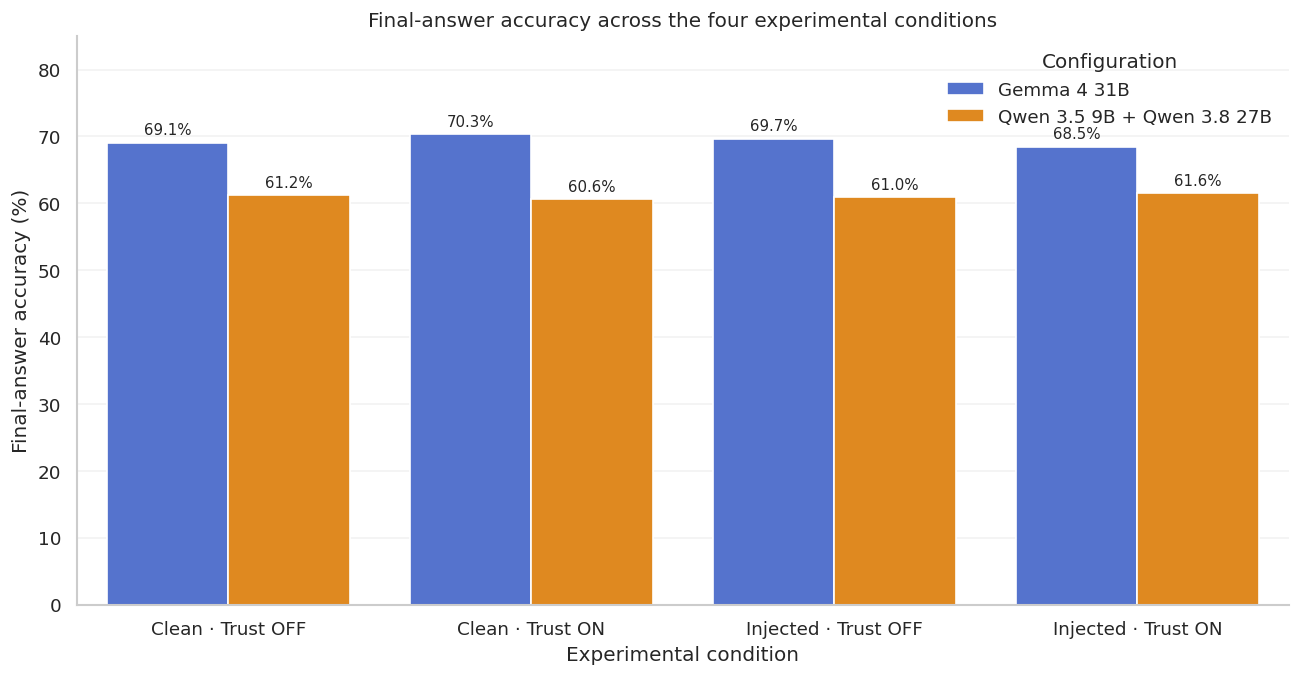

In [9]:
condition_order = ["baseline_off", "baseline_on", "fork_off", "fork_on"]
accuracy_plot = accuracy_table.copy()

fig, ax = plt.subplots(figsize=(11, 5.8))
sns.barplot(
    data=accuracy_plot,
    x="Condition label",
    y="Accuracy (%)",
    hue="Experiment",
    order=[CONDITION_LABELS[c] for c in condition_order],
    palette=PALETTE,
    errorbar=None,
    ax=ax,
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3, fontsize=9)

ax.set(title="Final-answer accuracy across the four experimental conditions",
       xlabel="Experimental condition", ylabel="Final-answer accuracy (%)", ylim=(0, 85))
ax.legend(title="Configuration", frameon=False)
plt.xticks(rotation=0)
plt.tight_layout()
save_figure(fig, "figure_01_accuracy_by_condition.png")
plt.show()

I also compare trust ON and OFF on the same task. The paired table counts tasks where trust helped, harmed or made no difference. I use an exact paired test on the tasks where the two conditions disagree, then adjust the four planned tests with Holm correction.

In [10]:
comparisons = {
    "Clean": ("baseline_off", "baseline_on"),
    "Injected": ("fork_off", "fork_on"),
}

paired_effect_rows = []
for experiment_name, wide in results_wide.items():
    for scenario, (off_col, on_col) in comparisons.items():
        if scenario == "Clean":
            paired_wide = wide.dropna(subset=[off_col, on_col])
        else:
            # For the attack comparison, keep only tasks where both runs
            # received the exact same successful injected message and mode.
            off_records = trace_records[experiment_name]["fork_off"]
            on_records = trace_records[experiment_name]["fork_on"]
            matched_attack_ids = []
            for task_id in set(off_records) & set(on_records):
                inj_off = off_records[task_id]["injection"]
                inj_on = on_records[task_id]["injection"]
                if (inj_off["eligible"] and inj_on["eligible"]
                    and inj_off["corrupted_hash"]
                    and inj_off["corrupted_hash"] == inj_on["corrupted_hash"]
                    and inj_off["fm_id"] == inj_on["fm_id"]):
                    matched_attack_ids.append(task_id)
            paired_wide = wide.loc[sorted(matched_attack_ids)].dropna(subset=[off_col, on_col])
        off = paired_wide[off_col]
        on = paired_wide[on_col]
        both_correct = int(((off == 1) & (on == 1)).sum())
        both_wrong = int(((off == 0) & (on == 0)).sum())
        helped = int(((off == 0) & (on == 1)).sum())
        harmed = int(((off == 1) & (on == 0)).sum())
        discordant = helped + harmed
        p = 1.0 if discordant == 0 else binomtest(helped, discordant, p=0.5, alternative="two-sided").pvalue
        paired_effect_rows.append({
            "Tasks": len(paired_wide),
            "Experiment": experiment_name,
            "Configuration": SHORT_NAMES[experiment_name],
            "Scenario": scenario,
            "Both correct": both_correct,
            "Both incorrect": both_wrong,
            "Trust helped": helped,
            "Trust harmed": harmed,
            "Net correct answers": helped - harmed,
            "Discordant pairs": discordant,
            "Exact p": p,
        })

paired_effect_table = pd.DataFrame(paired_effect_rows)
paired_effect_table["Holm-adjusted p"] = multipletests(paired_effect_table["Exact p"], method="holm")[1]
display(paired_effect_table.round(4))


# I combine absolute accuracy and paired changes in one compact table.
# The attack rows use only tasks with exactly matched successful injections.
main_performance_rows = []
for _, result in paired_effect_table.iterrows():
    experiment_name = result["Experiment"]
    scenario = result["Scenario"]
    off_col, on_col = comparisons[scenario]
    wide = results_wide[experiment_name]

    if scenario == "Clean":
        paired = wide[[off_col, on_col]].dropna()
    else:
        off_records = trace_records[experiment_name]["fork_off"]
        on_records = trace_records[experiment_name]["fork_on"]
        matched_ids = []
        for task_id in set(off_records) & set(on_records):
            a = off_records[task_id]["injection"]
            b = on_records[task_id]["injection"]
            if (a["eligible"] and b["eligible"] and a["corrupted_hash"]
                and a["corrupted_hash"] == b["corrupted_hash"]
                and a["fm_id"] == b["fm_id"]):
                matched_ids.append(task_id)
        paired = wide.loc[sorted(matched_ids), [off_col, on_col]].dropna()

    main_performance_rows.append({
        "Configuration": SHORT_NAMES[experiment_name],
        "Scenario": scenario,
        "Paired tasks": len(paired),
        "Accuracy OFF (%)": 100 * paired[off_col].mean(),
        "Accuracy ON (%)": 100 * paired[on_col].mean(),
        "Trust helped": int(result["Trust helped"]),
        "Trust harmed": int(result["Trust harmed"]),
        "Net correct answers": int(result["Net correct answers"]),
        "Holm-adjusted p": result["Holm-adjusted p"],
    })

main_performance_table = pd.DataFrame(main_performance_rows)
display(main_performance_table.round(2))
save_table(main_performance_table, "table_04_main_performance")


,Tasks,Experiment,Configuration,Scenario,Both correct,Both incorrect,Trust helped,Trust harmed,Net correct answers,Discordant pairs,Exact p,Holm-adjusted p
0,165,Gemma 4 31B,Gemma,Clean,113,48,3,1,2,4,0.6250,1.0
1,157,Gemma 4 31B,Gemma,Injected,105,42,4,6,-2,10,0.7539,1.0
2,165,Qwen 3.5 9B + Qwen 3.8 27B,Qwen,Clean,89,53,11,12,-1,23,1.0000,1.0
3,164,Qwen 3.5 9B + Qwen 3.8 27B,Qwen,Injected,91,54,10,9,1,19,1.0000,1.0


,Configuration,Scenario,Paired tasks,Accuracy OFF (%),Accuracy ON (%),Trust helped,Trust harmed,Net correct answers,Holm-adjusted p
0,Gemma,Clean,165,69.09,70.30,3,1,2,1.0
1,Gemma,Injected,157,70.70,69.43,4,6,-2,1.0
2,Qwen,Clean,165,61.21,60.61,11,12,-1,1.0
3,Qwen,Injected,164,60.98,61.59,10,9,1,1.0


Saved /content/results_outputs/tables/table_04_main_performance.csv and /content/results_outputs/tables/table_04_main_performance.tex


I then show the allocator's average effect by GAIA difficulty. For each task, I average the clean-condition change and the injected-condition change. This gives one paired effect per task. The horizontal point plot shows the mean change in percentage points and a task-level bootstrap 95% interval.

In [11]:
allocator_effect_rows = []
for experiment_name, wide in results_wide.items():
    levels = benchmark_tasks.set_index("task_id")["level"]
    off_records = trace_records[experiment_name]["fork_off"]
    on_records = trace_records[experiment_name]["fork_on"]
    matched_attack_ids = []
    for task_id in set(off_records) & set(on_records):
        inj_off = off_records[task_id]["injection"]
        inj_on = on_records[task_id]["injection"]
        if (inj_off["eligible"] and inj_on["eligible"]
            and inj_off["corrupted_hash"]
            and inj_off["corrupted_hash"] == inj_on["corrupted_hash"]
            and inj_off["fm_id"] == inj_on["fm_id"]):
            matched_attack_ids.append(task_id)
    paired = wide.loc[sorted(matched_attack_ids), ["baseline_off", "baseline_on", "fork_off", "fork_on"]].dropna().copy()
    paired["Level"] = levels.loc[paired.index]
    paired["Clean effect"] = paired["baseline_on"] - paired["baseline_off"]
    paired["Injected effect"] = paired["fork_on"] - paired["fork_off"]
    paired["Effect (pp)"] = 100 * (paired["Clean effect"] + paired["Injected effect"]) / 2
    for task_id, row in paired.iterrows():
        allocator_effect_rows.append({
            "Experiment": experiment_name,
            "Configuration": SHORT_NAMES[experiment_name],
            "Task": task_id,
            "Level": int(row["Level"]),
            "Effect (pp)": row["Effect (pp)"],
        })

allocator_effect_tasks = pd.DataFrame(allocator_effect_rows)
allocator_effect_summary = (
    allocator_effect_tasks.groupby(["Experiment", "Configuration", "Level"])
    .agg(Tasks=("Task", "nunique"), Mean_effect_pp=("Effect (pp)", "mean"))
    .reset_index()
)
ci_rows = []
for _, row in allocator_effect_summary.iterrows():
    vals = allocator_effect_tasks[
        (allocator_effect_tasks["Experiment"] == row["Experiment"])
        & (allocator_effect_tasks["Level"] == row["Level"])
    ]["Effect (pp)"].to_numpy()
    lo, hi = bootstrap_mean_ci(vals)
    ci_rows.append({"Experiment": row["Experiment"], "Level": row["Level"], "CI lower": lo, "CI upper": hi})
allocator_effect_summary = allocator_effect_summary.merge(pd.DataFrame(ci_rows), on=["Experiment", "Level"])
allocator_effect_summary["Label"] = allocator_effect_summary.apply(
    lambda r: f"{r['Configuration']} · Level {r['Level']} (n={r['Tasks']})", axis=1
)
display(allocator_effect_summary[["Configuration", "Level", "Tasks", "Mean_effect_pp", "CI lower", "CI upper"]].round(2))


,Configuration,Level,Tasks,Mean_effect_pp,CI lower,CI upper
0,Gemma,1,52,0.96,-2.88,5.77
1,Gemma,2,80,0.00,-2.50,2.50
2,Gemma,3,25,-2.00,-12.00,8.00
3,Qwen,1,52,4.81,0.00,9.62
4,Qwen,2,86,-1.74,-6.99,3.49
5,Qwen,3,26,-3.85,-15.43,9.62


Saved /content/results_outputs/figures/figure_02_allocator_effect_by_level.png


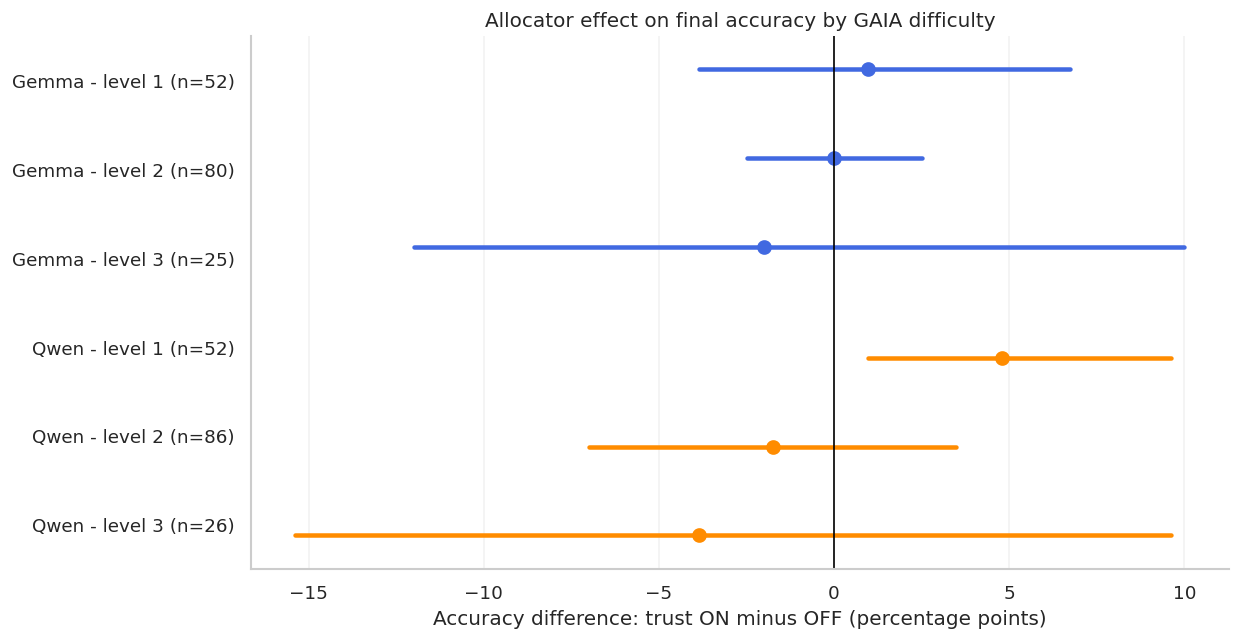

In [12]:
plot_data = allocator_effect_tasks.copy()
plot_data["Label"] = plot_data.apply(
    lambda r: f"{SHORT_NAMES[r['Experiment']]} - level {r['Level']}", axis=1
)
label_order = []
for experiment_name in RUN_DIRS:
    for level in [1, 2, 3]:
        n = int((plot_data[(plot_data["Experiment"] == experiment_name) & (plot_data["Level"] == level)]["Task"]).nunique())
        label_order.append(f"{SHORT_NAMES[experiment_name]} - level {level} (n={n})")
plot_data["Label"] = plot_data.apply(
    lambda r: f"{SHORT_NAMES[r['Experiment']]} - level {r['Level']} (n="
              f"{plot_data[(plot_data['Experiment'] == r['Experiment']) & (plot_data['Level'] == r['Level'])]['Task'].nunique()})",
    axis=1,
)
label_order = []
for experiment_name in RUN_DIRS:
    for level in [1, 2, 3]:
        n = plot_data[(plot_data["Experiment"] == experiment_name) & (plot_data["Level"] == level)]["Task"].nunique()
        label_order.append(f"{SHORT_NAMES[experiment_name]} - level {level} (n={n})")
fig, ax = plt.subplots(figsize=(10.5, 5.5))
sns.pointplot(
    data=plot_data,
    x="Effect (pp)",
    y="Label",
    hue="Experiment",
    order=label_order,
    hue_order=list(RUN_DIRS.keys()),
    palette=PALETTE,
    orient="h",
    errorbar=("ci", 95),
    n_boot=N_BOOT,
    dodge=0.25,
    markers="o",
    linestyles="none",
    ax=ax,
)
ax.axvline(0, color="black", linewidth=1)
ax.set(title="Allocator effect on final accuracy by GAIA difficulty",
       xlabel="Accuracy difference: trust ON minus OFF (percentage points)", ylabel="")
ax.legend_.remove()
ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
save_figure(fig, "figure_02_allocator_effect_by_level.png")
plt.show()


The last main-performance check asks whether the injected condition itself reduces accuracy. I compare injected versus clean runs separately with trust OFF and with trust ON. This tells me whether the debate system already recovers from the injected message without the allocator.

In [13]:
attack_impact_rows = []
for experiment_name, wide in results_wide.items():
    for trust_status, clean_col, injected_col in [
        ("Trust OFF", "baseline_off", "fork_off"),
        ("Trust ON", "baseline_on", "fork_on"),
    ]:
        eligible_ids = set(
            dfs[experiment_name].loc[
                (dfs[experiment_name]["condition"] == injected_col)
                & (dfs[experiment_name]["eligible"]),
                "task_id",
            ]
        )
        valid_wide = wide.loc[sorted(eligible_ids)]
        clean = valid_wide[clean_col]
        injected = valid_wide[injected_col]
        changed_to_wrong = int(((clean == 1) & (injected == 0)).sum())
        changed_to_correct = int(((clean == 0) & (injected == 1)).sum())
        discordant = changed_to_wrong + changed_to_correct
        p = 1.0 if discordant == 0 else binomtest(changed_to_correct, discordant, p=0.5).pvalue
        attack_impact_rows.append({
            "Configuration": SHORT_NAMES[experiment_name],
            "Trust condition": trust_status,
            "Clean accuracy (%)": clean.mean() * 100,
            "Injected accuracy (%)": injected.mean() * 100,
            "Attack effect (pp)": (injected.mean() - clean.mean()) * 100,
            "Correct to incorrect": changed_to_wrong,
            "Incorrect to correct": changed_to_correct,
            "Exact paired p": p,
        })
attack_impact_table = pd.DataFrame(attack_impact_rows)
attack_impact_table["Holm-adjusted p"] = multipletests(attack_impact_table["Exact paired p"], method="holm")[1]
display(attack_impact_table.round(3))
save_table(attack_impact_table, "table_07_injection_effect_on_accuracy")

,Configuration,Trust condition,Clean accuracy (%),Injected accuracy (%),Attack effect (pp),Correct to incorrect,Incorrect to correct,Exact paired p,Holm-adjusted p
0,Gemma,Trust OFF,69.091,69.697,0.606,3,4,1.000,1.0
1,Gemma,Trust ON,70.303,68.485,-1.818,5,2,0.453,1.0
2,Qwen,Trust OFF,61.585,60.976,-0.610,9,8,1.000,1.0
3,Qwen,Trust ON,60.976,61.585,0.610,12,13,1.000,1.0


Saved /content/results_outputs/tables/table_07_injection_effect_on_accuracy.csv and /content/results_outputs/tables/table_07_injection_effect_on_accuracy.tex


## 6. Main research question: step-level recovery

I measure recovery as the first correct agent message after the injected first message. I count the next five messages in debate order. If no later message is correct, I record `6` to mean “no recovery in the observed debate”. This measures message steps, not elapsed time.

I only compare tasks where the trust-OFF and trust-ON traces contain the same successful injected message, the injected answer is wrong in both traces, and both runs contain the expected six-message debate. This makes the recovery comparison fairer.

In [14]:
expected_order = [
    ("Agent1", 1), ("Agent2", 1), ("Agent3", 1),
    ("Agent1", 2), ("Agent2", 2), ("Agent3", 2),
]

recovery_pairs = []
recovery_audit_rows = []
for experiment_name in RUN_DIRS:
    off_data = trace_records[experiment_name]["fork_off"]
    on_data = trace_records[experiment_name]["fork_on"]
    common_ids = set(off_data) & set(on_data)
    matched = []
    counts = {"Paired raw traces": len(common_ids), "Both eligible": 0, "Same injected text": 0,
              "First message wrong in both": 0, "Complete six-message pairs": 0}

    for task_id in common_ids:
        off, on = off_data[task_id], on_data[task_id]
        inj_off, inj_on = off["injection"], on["injection"]
        if not (inj_off["eligible"] and inj_on["eligible"] and inj_off["corrupted_hash"] and inj_on["corrupted_hash"]):
            continue
        counts["Both eligible"] += 1
        if inj_off["corrupted_hash"] != inj_on["corrupted_hash"]:
            continue
        counts["Same injected text"] += 1
        msgs_off, msgs_on = off["messages"], on["messages"]
        if not msgs_off or not msgs_on:
            continue
        if not (msgs_off[0]["step_correct"] is False and msgs_on[0]["step_correct"] is False):
            continue
        counts["First message wrong in both"] += 1
        if len(msgs_off) != 6 or len(msgs_on) != 6:
            continue
        if any((m["source"], m["round"]) != expected for m, expected in zip(msgs_off, expected_order)):
            continue
        if any((m["source"], m["round"]) != expected for m, expected in zip(msgs_on, expected_order)):
            continue
        counts["Complete six-message pairs"] += 1
        matched.append(task_id)
        recovery_pairs.append({
            "Experiment": experiment_name,
            "Configuration": SHORT_NAMES[experiment_name],
            "Task": task_id,
            "Level": difficulty_map[task_id],
            "OFF messages": msgs_off,
            "ON messages": msgs_on,
        })
    recovery_audit_rows.append({"Configuration": SHORT_NAMES[experiment_name], **counts})

recovery_audit_table = pd.DataFrame(recovery_audit_rows)
display(recovery_audit_table)
save_table(recovery_audit_table, "table_08_recovery_cohort")

,Configuration,Paired raw traces,Both eligible,Same injected text,First message wrong in both,Complete six-message pairs
0,Gemma,165,165,157,148,148
1,Qwen,165,164,164,136,134


In [15]:
def first_correct_after_injection(messages):
    for position, message in enumerate(messages[1:], start=1):
        if message["step_correct"]:
            return position
    return 6

recovery_rows = []
for pair in recovery_pairs:
    for trust, key in [("OFF", "OFF messages"), ("ON", "ON messages")]:
        pos = first_correct_after_injection(pair[key])
        recovery_rows.append({
            "Experiment": pair["Experiment"],
            "Configuration": pair["Configuration"],
            "Task": pair["Task"],
            "Level": pair["Level"],
            "Trust": trust,
            "First correct position": pos,
            "Recovered during debate": pos <= 5,
        })
recovery_df = pd.DataFrame(recovery_rows)

recovery_summary = (
    recovery_df.groupby(["Configuration", "Trust"])
    .agg(
        Tasks=("Task", "nunique"),
        Recovery_rate_pct=("Recovered during debate", lambda x: 100 * x.mean()),
        Median_first_correct_position=("First correct position", "median"),
        Mean_first_correct_position=("First correct position", "mean"),
    )
    .reset_index()
)

test_rows = []
for experiment_name in RUN_DIRS:
    sub = recovery_df[recovery_df["Experiment"] == experiment_name]
    paired = sub.pivot(index="Task", columns="Trust", values="First correct position").dropna()
    faster = int((paired["ON"] < paired["OFF"]).sum())
    slower = int((paired["ON"] > paired["OFF"]).sum())
    tied = int((paired["ON"] == paired["OFF"]).sum())
    discordant = faster + slower
    p = 1.0 if discordant == 0 else binomtest(faster, discordant, p=0.5).pvalue
    test_rows.append({
        "Configuration": SHORT_NAMES[experiment_name],
        "Paired tasks": len(paired),
        "Trust faster": faster,
        "Trust slower": slower,
        "Tied": tied,
        "Mean position change (ON - OFF)": (paired["ON"] - paired["OFF"]).mean(),
        "Exact sign-test p": p,
    })
recovery_test_table = pd.DataFrame(test_rows)
recovery_test_table["Holm-adjusted p"] = multipletests(recovery_test_table["Exact sign-test p"], method="holm")[1]
display(recovery_summary.round(2))
display(recovery_test_table.round(3))
# I merge the descriptive recovery rates with the paired sign test.
recovery_rate_wide = recovery_summary.pivot(
    index="Configuration", columns="Trust",
    values=["Tasks", "Recovery_rate_pct", "Median_first_correct_position", "Mean_first_correct_position"]
)
recovery_rate_wide.columns = [f"{metric}_{trust}" for metric, trust in recovery_rate_wide.columns]
recovery_results_table = recovery_rate_wide.reset_index().merge(
    recovery_test_table.drop(columns=["Experiment"], errors="ignore"),
    on="Configuration", how="left"
)
display(recovery_results_table.round(3))
save_table(recovery_results_table, "table_09_recovery_results")

,Configuration,Trust,Tasks,Recovery_rate_pct,Median_first_correct_position,Mean_first_correct_position
0,Gemma,OFF,148,72.97,1.0,2.41
1,Gemma,ON,148,71.62,1.0,2.45
2,Qwen,OFF,134,59.70,1.0,3.10
3,Qwen,ON,134,58.96,1.0,3.15


,Configuration,Paired tasks,Trust faster,Trust slower,Tied,Mean position change (ON - OFF),Exact sign-test p,Holm-adjusted p
0,Gemma,148,7,7,134,0.034,1.000,1.0
1,Qwen,134,8,12,114,0.052,0.503,1.0


,Configuration,Tasks_OFF,Tasks_ON,Recovery_rate_pct_OFF,Recovery_rate_pct_ON,Median_first_correct_position_OFF,Median_first_correct_position_ON,Mean_first_correct_position_OFF,Mean_first_correct_position_ON,Paired tasks,Trust faster,Trust slower,Tied,Mean position change (ON - OFF),Exact sign-test p,Holm-adjusted p
0,Gemma,148.0,148.0,72.973,71.622,1.0,1.0,2.412,2.446,148,7,7,134,0.034,1.000,1.0
1,Qwen,134.0,134.0,59.701,58.955,1.0,1.0,3.097,3.149,134,8,12,114,0.052,0.503,1.0


Saved /content/results_outputs/tables/table_09_recovery_results.csv and /content/results_outputs/tables/table_09_recovery_results.tex


I plot the cumulative share of tasks that have recovered after each subsequent agent message. I split the figure by GAIA level so that a strong result on the more common Level 2 tasks does not hide a different pattern on Level 1 or Level 3.

Saved /content/results_outputs/figures/figure_03_recovery_by_level.png


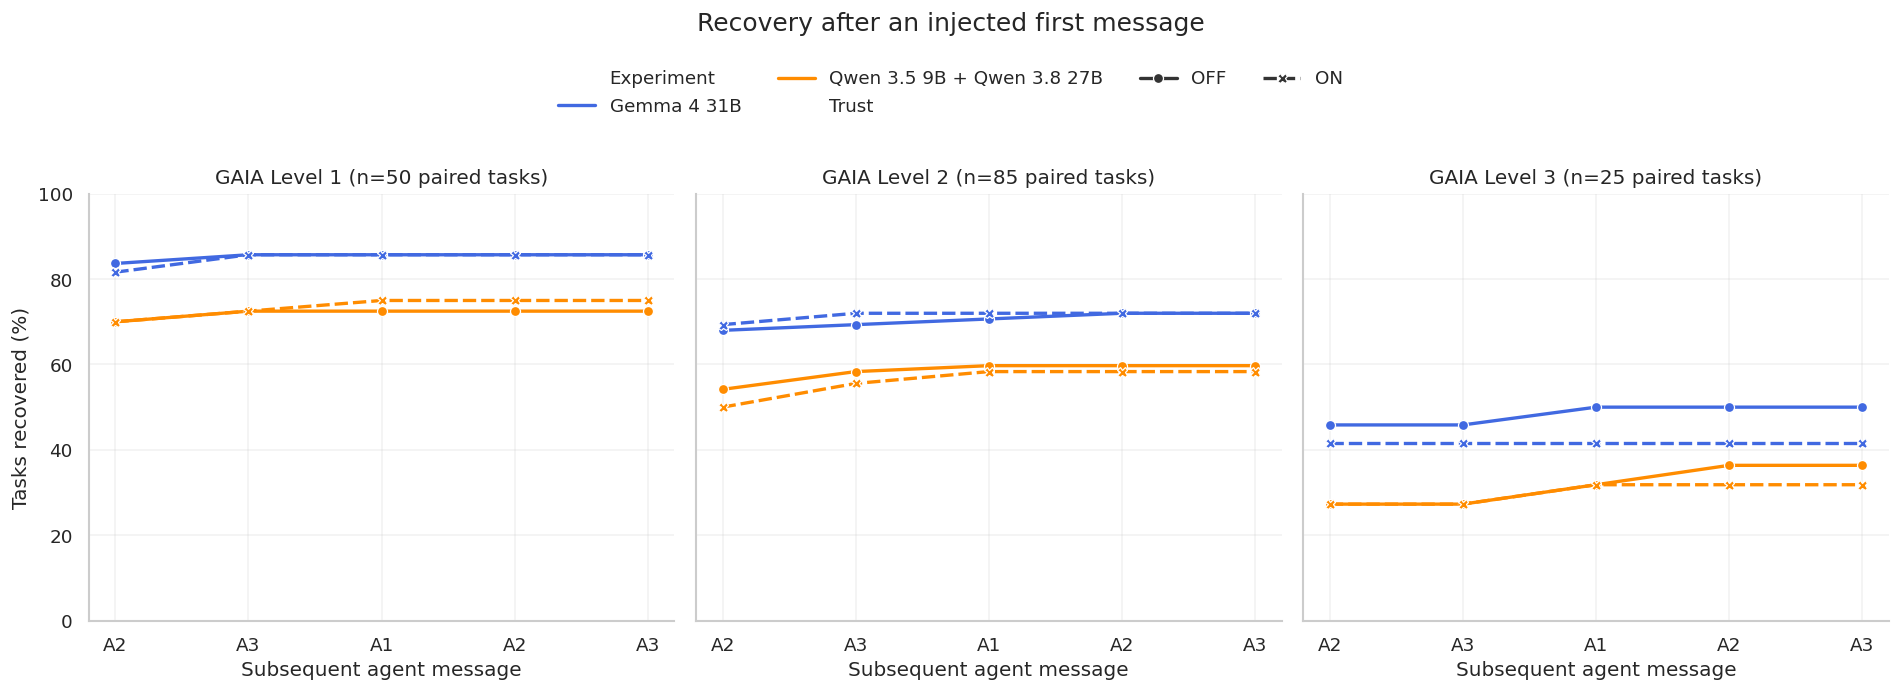

In [16]:
message_labels = {
    1: "Agent 2 · R1", 2: "Agent 3 · R1", 3: "Agent 1 · R2",
    4: "Agent 2 · R2", 5: "Agent 3 · R2",
}
recovery_curve_rows = []
for (experiment_name, trust, level), group in recovery_df.groupby(["Experiment", "Trust", "Level"]):
    for position in range(1, 6):
        recovery_curve_rows.append({
            "Experiment": experiment_name,
            "Configuration": SHORT_NAMES[experiment_name],
            "Trust": trust,
            "Level": level,
            "Position": position,
            "Message": message_labels[position],
            "Recovery (%)": 100 * (group["First correct position"] <= position).mean(),
            "Tasks": group["Task"].nunique(),
        })
recovery_curve_df = pd.DataFrame(recovery_curve_rows)

fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharey=True)
for ax, level in zip(axes, [1, 2, 3]):
    data = recovery_curve_df[recovery_curve_df["Level"] == level]
    sns.lineplot(
        data=data,
        x="Position", y="Recovery (%)",
        hue="Experiment", style="Trust",
        hue_order=list(RUN_DIRS.keys()),
        style_order=["OFF", "ON"],
        palette=PALETTE, markers=True, dashes=True,
        estimator=None, errorbar=None, linewidth=2, ax=ax,
    )
    n = recovery_df[recovery_df["Level"] == level]["Task"].nunique()
    ax.set(title=f"GAIA Level {level} (n={n} paired tasks)",
           xlabel="Subsequent agent message", ylabel="Tasks recovered (%)", ylim=(0, 100))
    ax.set_xticks(range(1, 6), ["A2", "A3", "A1", "A2", "A3"])
    if ax.legend_:
        ax.legend_.remove()
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=4, frameon=False, bbox_to_anchor=(0.5, 1.08))
fig.suptitle("Recovery after an injected first message", y=1.15, fontsize=15)
plt.tight_layout()
save_figure(fig, "figure_03_recovery_by_level.png")
plt.show()

## 7. Validation question 1: do trust scores distinguish incorrect messages?

I test this using the `step_correct` label recorded for each agent message. The trust allocator does not see the GAIA ground truth, so this lets me compare its judgement with an external correctness label.

I treat **low trust as a signal that a message is incorrect**. The four groups are:

- clean messages from `baseline_on`;
- natural downstream messages from successfully injected `fork_on` runs;
- injected first messages only;
- all scored messages from clean and successfully injected runs combined.

I use ROC-AUC because it measures whether the score ranks incorrect messages below correct ones without forcing me to choose a warning threshold.



In [17]:
message_rows = []
missing_trust_rows = []

for experiment_name in RUN_DIRS:
    for condition in ["baseline_on", "fork_on"]:
        for task_id, trace in trace_records[experiment_name][condition].items():
            injected_run = condition == "fork_on" and trace["injection"]["eligible"]
            trust_by_index = {
                item.get("message_index"): item
                for item in trace["trust_history"]
                if item.get("message_index") is not None
            }
            for message in trace["messages"]:
                msg_index = message["log_index"]
                trust_record = trust_by_index.get(msg_index)
                if trust_record is None or not isinstance(trust_record.get("trust_score"), (int, float)):
                    missing_trust_rows.append({"Experiment": experiment_name, "Condition": condition, "Task": task_id, "Message index": msg_index})
                    continue
                is_injected = bool(injected_run and msg_index == 0)
                message_rows.append({
                    "Experiment": experiment_name,
                    "Configuration": SHORT_NAMES[experiment_name],
                    "Condition": condition,
                    "Task": task_id,
                    "Level": difficulty_map[task_id],
                    "Message index": msg_index,
                    "Agent": message["source"],
                    "Round": message["round"],
                    "Correct": bool(message["step_correct"]),
                    "Trust score": float(trust_record["trust_score"]),
                    "Injected": is_injected,
                    "Successful injection": bool(injected_run),
                })

message_df = pd.DataFrame(message_rows)
print("Scored messages:", len(message_df))
print("Messages without a usable trust score:", len(missing_trust_rows))

Scored messages: 3937
Messages without a usable trust score: 8


In [18]:
natural_clean = message_df[message_df["Condition"] == "baseline_on"].copy()
natural_after_injection = message_df[
    (message_df["Condition"] == "fork_on")
    & (message_df["Successful injection"])
    & (~message_df["Injected"])
].copy()
injected_only = message_df[message_df["Injected"]].copy()
successful_attacked_messages = message_df[
    (message_df["Condition"] == "fork_on")
    & (message_df["Successful injection"])
].copy()
all_runs = pd.concat(
    [natural_clean, successful_attacked_messages],
    ignore_index=True,
)

cohorts = {
    "Natural messages (clean runs)": natural_clean,
    "Natural messages (after injection)": natural_after_injection,
    "Injected first messages": injected_only,
    "All clean + injected runs": all_runs,
}

cohort_composition = []
for cohort_name, data in cohorts.items():
    for experiment_name in RUN_DIRS:
        sub = data[data["Experiment"] == experiment_name]
        cohort_composition.append({
            "Message group": cohort_name,
            "Configuration": SHORT_NAMES[experiment_name],
            "Messages": len(sub),
            "Correct": int(sub["Correct"].sum()),
            "Incorrect": int((~sub["Correct"]).sum()),
        })
display(pd.DataFrame(cohort_composition))

,Message group,Configuration,Messages,Correct,Incorrect
0,Natural messages (clean runs),Gemma,989,676,313
1,Natural messages (clean runs),Qwen,980,563,417
2,Natural messages (after injection),Gemma,825,559,266
3,Natural messages (after injection),Qwen,809,483,326
4,Injected first messages,Gemma,165,9,156
5,Injected first messages,Qwen,163,28,135
6,All clean + injected runs,Gemma,1979,1244,735
7,All clean + injected runs,Qwen,1952,1074,878


I calculate the ROC-AUC and task-cluster bootstrap confidence interval for each message group. The bootstrap resamples whole tasks, keeping the messages from a sampled conversation together. This avoids pretending that six messages from one task are six independent tasks.

In [19]:
vq1_rows = []
vq1_boot_rows = []
for cohort_index, (cohort_name, data) in enumerate(cohorts.items()):
    for model_index, experiment_name in enumerate(RUN_DIRS):
        sub = data[data["Experiment"] == experiment_name].dropna(subset=["Correct", "Trust score"]).copy()
        correct_scores = sub.loc[sub["Correct"], "Trust score"]
        incorrect_scores = sub.loc[~sub["Correct"], "Trust score"]
        auc, lo, hi, boot = cluster_bootstrap_auc(
            sub, n_boot=1000,
            seed=RANDOM_SEED + cohort_index * 10 + model_index,
        )
        vq1_rows.append({
            "Message group": cohort_name,
            "Experiment": experiment_name,
            "Configuration": SHORT_NAMES[experiment_name],
            "Messages": len(sub),
            "Incorrect messages": len(incorrect_scores),
            "Mean trust (correct)": correct_scores.mean(),
            "Mean trust (incorrect)": incorrect_scores.mean(),
            "ROC-AUC": auc,
            "95% CI lower": lo,
            "95% CI upper": hi,
        })
        for value in boot:
            vq1_boot_rows.append({
                "Message group": cohort_name,
                "Experiment": experiment_name,
                "Configuration": SHORT_NAMES[experiment_name],
                "AUC bootstrap": value,
            })

vq1_table = pd.DataFrame(vq1_rows)
display(vq1_table.round(3))
save_table(vq1_table, "table_11_vq1_trust_discrimination")
vq1_boot_df = pd.DataFrame(vq1_boot_rows)

# I also report how often each maxim reaches the top of the scale in clean runs.
maxim_rows = []
for experiment_name in RUN_DIRS:
    for task_id, trace in trace_records[experiment_name]["baseline_on"].items():
        for item in trace["trust_history"]:
            for maxim, score in (item.get("maxim_scores") or {}).items():
                if isinstance(score, (int, float)):
                    maxim_rows.append({
                        "Experiment": experiment_name,
                        "Configuration": SHORT_NAMES[experiment_name],
                        "Task": task_id,
                        "Maxim": maxim.title(),
                        "Score": float(score),
                    })
maxim_df = pd.DataFrame(maxim_rows)
maxim_table = (
    maxim_df.groupby(["Configuration", "Maxim"])
    .agg(Messages=("Score", "count"), Mean_score=("Score", "mean"), Share_at_5_pct=("Score", lambda x: 100 * (x == 5).mean()))
    .reset_index()
)
display(maxim_table.round(2))
save_table(maxim_table, "table_12_clean_gricean_scores")

,Message group,Experiment,Configuration,Messages,Incorrect messages,Mean trust (correct),Mean trust (incorrect),ROC-AUC,95% CI lower,95% CI upper
0,Natural messages (clean runs),Gemma 4 31B,Gemma,989,313,4.890,4.735,0.566,0.523,0.613
1,Natural messages (clean runs),Qwen 3.5 9B + Qwen 3.8 27B,Qwen,980,417,4.574,3.447,0.818,0.764,0.868
2,Natural messages (after injection),Gemma 4 31B,Gemma,825,266,4.944,4.743,0.605,0.558,0.651
3,Natural messages (after injection),Qwen 3.5 9B + Qwen 3.8 27B,Qwen,809,326,4.538,3.615,0.775,0.717,0.836
4,Injected first messages,Gemma 4 31B,Gemma,165,156,2.944,2.804,0.517,0.343,0.713
5,Injected first messages,Qwen 3.5 9B + Qwen 3.8 27B,Qwen,163,135,3.330,2.602,0.747,0.650,0.842
6,All clean + injected runs,Gemma 4 31B,Gemma,1979,735,4.900,4.328,0.665,0.628,0.702
7,All clean + injected runs,Qwen 3.5 9B + Qwen 3.8 27B,Qwen,1952,878,4.525,3.380,0.817,0.768,0.864


Saved /content/results_outputs/tables/table_11_vq1_trust_discrimination.csv and /content/results_outputs/tables/table_11_vq1_trust_discrimination.tex


,Configuration,Maxim,Messages,Mean_score,Share_at_5_pct
0,Gemma,Manner,989,4.98,98.89
1,Gemma,Quality,989,4.51,83.82
2,Gemma,Quantity,989,4.90,95.15
3,Gemma,Relation,989,4.98,98.99
4,Qwen,Manner,980,4.16,50.92
5,Qwen,Quality,980,3.79,36.22
6,Qwen,Quantity,980,3.99,42.96
7,Qwen,Relation,980,4.44,63.78


Saved /content/results_outputs/tables/table_12_clean_gricean_scores.csv and /content/results_outputs/tables/table_12_clean_gricean_scores.tex


The ROC curves show the trade-off between catching incorrect messages and falsely flagging correct ones. The upper-left corner is best. I show four panels so that the clean, downstream-after-injection, injected-only and pooled results remain distinct.

Saved /content/results_outputs/figures/figure_04_vq1_roc_curves.png


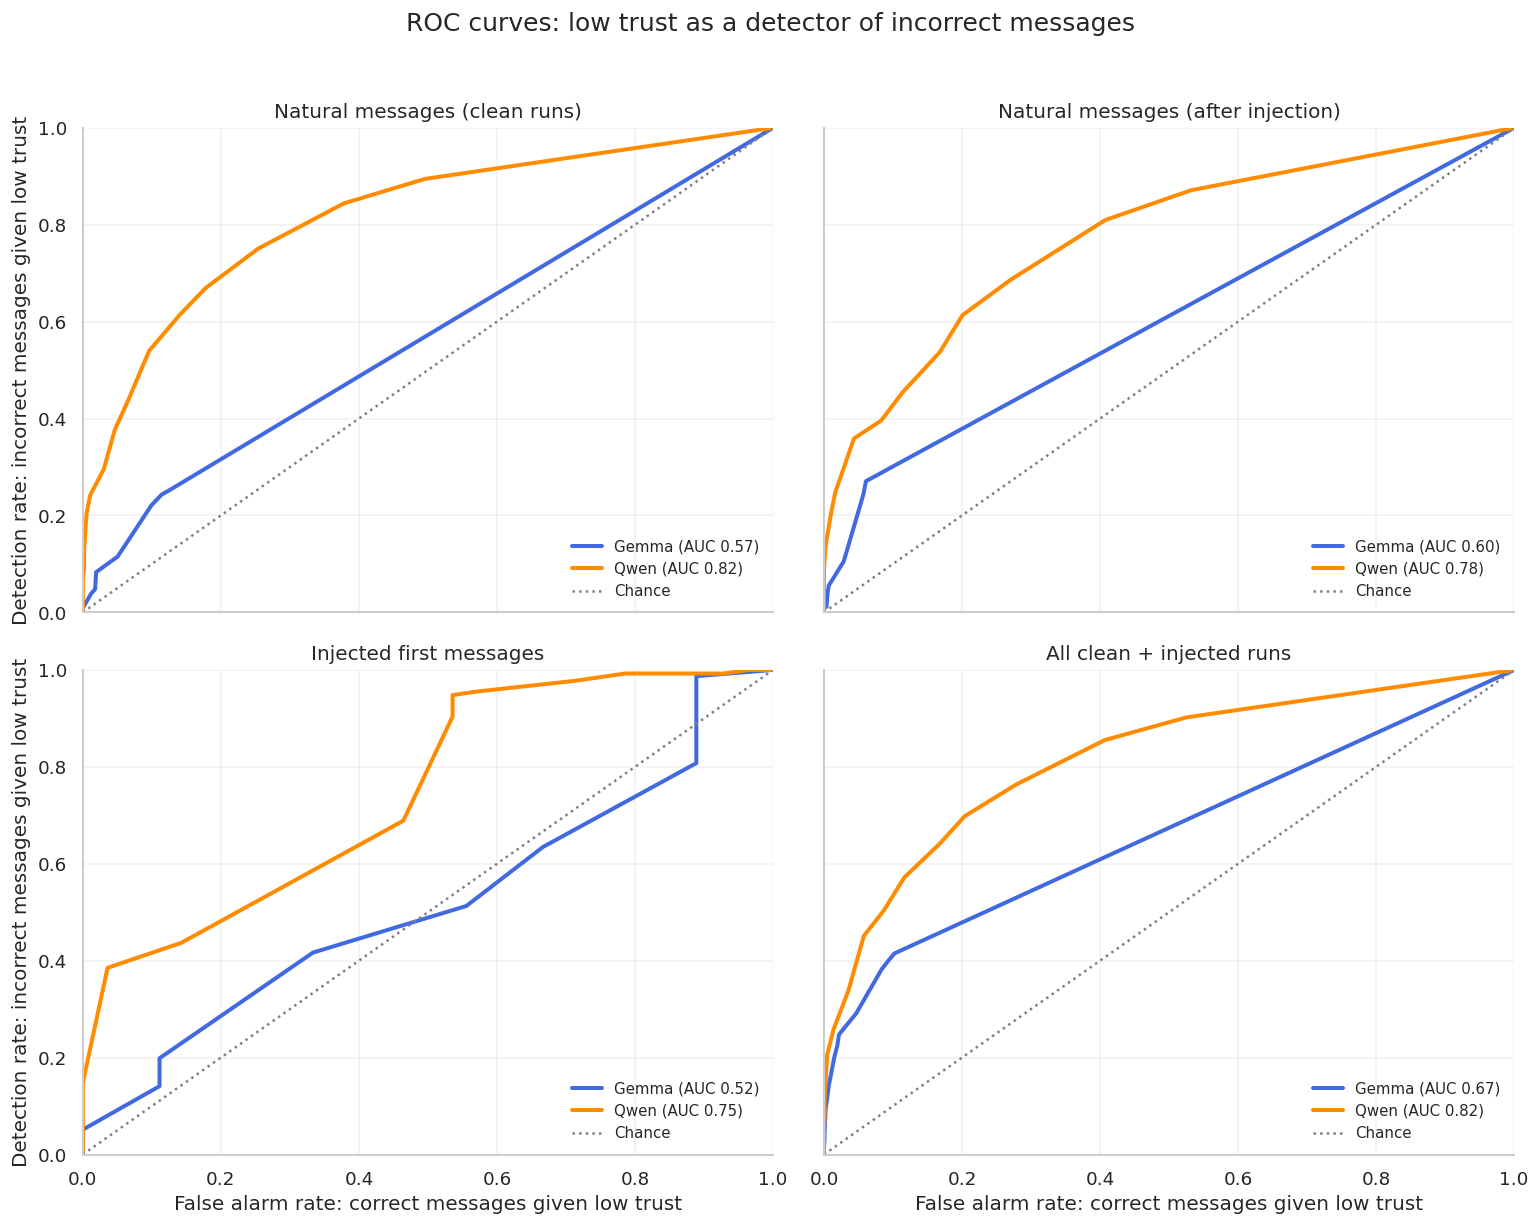

In [20]:
fig, axes = plt.subplots(2, 2, figsize=(13, 10), sharex=True, sharey=True)
axes = axes.flatten()
for ax, (cohort_name, data) in zip(axes, cohorts.items()):
    for experiment_name, color in PALETTE.items():
        sub = data[data["Experiment"] == experiment_name].dropna(subset=["Correct", "Trust score"])
        y_true = (~sub["Correct"].astype(bool)).astype(int)
        if y_true.nunique() < 2:
            continue
        fpr, tpr, _ = roc_curve(y_true, -sub["Trust score"])
        row = vq1_table[
            (vq1_table["Message group"] == cohort_name)
            & (vq1_table["Experiment"] == experiment_name)
        ].iloc[0]
        label = f"{SHORT_NAMES[experiment_name]} (AUC {row['ROC-AUC']:.2f})"
        sns.lineplot(x=fpr, y=tpr, estimator=None, errorbar=None, sort=False,
                     color=color, linewidth=2.4, label=label, ax=ax)
    sns.lineplot(x=[0, 1], y=[0, 1], estimator=None, errorbar=None,
                 color="gray", linestyle=":", linewidth=1.5, label="Chance", ax=ax)
    ax.set(title=cohort_name, xlabel="False alarm rate: correct messages given low trust",
           ylabel="Detection rate: incorrect messages given low trust", xlim=(0, 1), ylim=(0, 1))
    ax.legend(frameon=False, fontsize=9, loc="lower right")
fig.suptitle("ROC curves: low trust as a detector of incorrect messages", y=1.02, fontsize=15)
plt.tight_layout()
save_figure(fig, "figure_04_vq1_roc_curves.png")
plt.show()

I also check whether the clean-message discrimination changes with GAIA difficulty. To keep this figure readable, I show only the clean messages and the pooled clean-plus-injected messages. I use the same task-cluster bootstrap for the confidence intervals.

For the difficulty subgroups I use 500 bootstrap resamples. These estimates are secondary and the Level 3 group is small, so I treat the intervals as descriptive.

In [21]:
difficulty_vq1_rows = []
difficulty_vq1_boot_rows = []
for level in [1, 2, 3]:
    for cohort_name, source in [
        ("Natural clean", natural_clean),
        ("All runs", all_runs),
    ]:
        level_data = source[source["Level"] == level]
        for model_index, experiment_name in enumerate(RUN_DIRS):
            sub = level_data[level_data["Experiment"] == experiment_name]
            auc, lo, hi, boot = cluster_bootstrap_auc(
                sub, n_boot=500,
                seed=RANDOM_SEED + level * 100 + model_index * 10 + (0 if cohort_name == "Natural clean" else 1),
            )
            difficulty_vq1_rows.append({
                "Level": level,
                "Message group": cohort_name,
                "Experiment": experiment_name,
                "Configuration": SHORT_NAMES[experiment_name],
                "Messages": len(sub),
                "ROC-AUC": auc,
                "95% CI lower": lo,
                "95% CI upper": hi,
            })
            for value in boot:
                difficulty_vq1_boot_rows.append({
                    "Label": f"Level {level} · {cohort_name}",
                    "Experiment": experiment_name,
                    "Configuration": SHORT_NAMES[experiment_name],
                    "AUC bootstrap": value,
                })

difficulty_vq1_table = pd.DataFrame(difficulty_vq1_rows)
display(difficulty_vq1_table.round(3))

difficulty_vq1_boot = pd.DataFrame(difficulty_vq1_boot_rows)

,Level,Message group,Experiment,Configuration,Messages,ROC-AUC,95% CI lower,95% CI upper
0,1,Natural clean,Gemma 4 31B,Gemma,318,0.571,0.498,0.662
1,1,Natural clean,Qwen 3.5 9B + Qwen 3.8 27B,Qwen,318,0.788,0.672,0.886
2,1,All runs,Gemma 4 31B,Gemma,636,0.692,0.634,0.784
3,1,All runs,Qwen 3.5 9B + Qwen 3.8 27B,Qwen,630,0.786,0.685,0.886
4,2,Natural clean,Gemma 4 31B,Gemma,515,0.543,0.481,0.609
5,2,Natural clean,Qwen 3.5 9B + Qwen 3.8 27B,Qwen,510,0.802,0.714,0.872
6,2,All runs,Gemma 4 31B,Gemma,1031,0.644,0.593,0.694
7,2,All runs,Qwen 3.5 9B + Qwen 3.8 27B,Qwen,1017,0.811,0.742,0.876
8,3,Natural clean,Gemma 4 31B,Gemma,156,0.536,0.427,0.635
9,3,Natural clean,Qwen 3.5 9B + Qwen 3.8 27B,Qwen,152,0.771,0.623,0.892


Saved /content/results_outputs/figures/figure_05_vq1_auc_by_difficulty.png


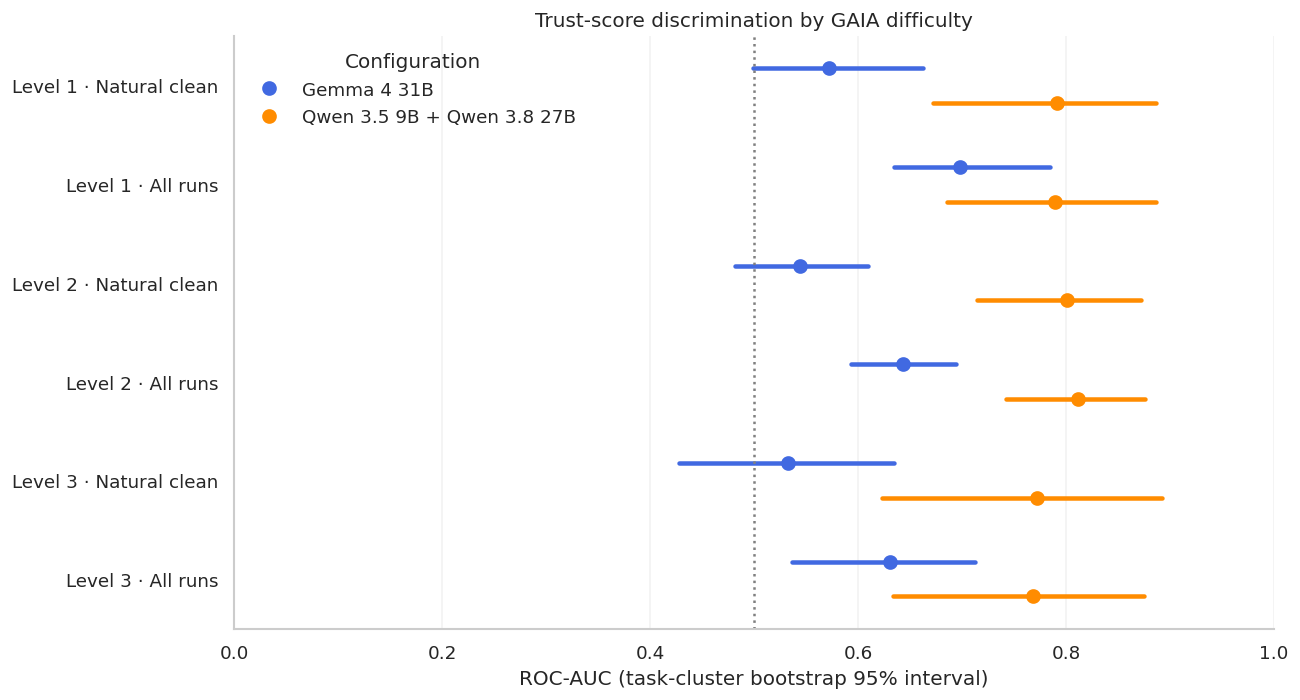

In [22]:
fig, ax = plt.subplots(figsize=(11, 6))
label_order = [
    f"Level {level} · {group}"
    for level in [1, 2, 3]
    for group in ["Natural clean", "All runs"]
]
sns.pointplot(
    data=difficulty_vq1_boot,
    x="AUC bootstrap", y="Label", hue="Experiment",
    order=label_order, hue_order=list(RUN_DIRS.keys()),
    palette=PALETTE, orient="h", errorbar=("pi", 95),
    n_boot=500, dodge=0.35, markers="o", linestyles="none", ax=ax,
)
ax.axvline(0.5, color="gray", linestyle=":", linewidth=1.5)
ax.set(title="Trust-score discrimination by GAIA difficulty",
       xlabel="ROC-AUC (task-cluster bootstrap 95% interval)", ylabel="", xlim=(0, 1))
ax.legend(title="Configuration", frameon=False)
plt.tight_layout()
save_figure(fig, "figure_05_vq1_auc_by_difficulty.png")
plt.show()

## 8. Validation question 2: does manipulation lower trust?

I pair the original Agent 1 message from `baseline_on` with the manipulated version from `fork_on`. I include a task only when the baseline message exactly matches the injector's recorded original text, the attacked message matches the recorded corrupted text, and both trust scores are available.

In [23]:
def trust_score_at(trace, message_index=0):
    for item in trace.get("trust_history", []):
        if item.get("message_index") == message_index:
            score = item.get("trust_score")
            if isinstance(score, (int, float)):
                return float(score)
    return np.nan

vq2_rows = []
vq2_exclusions = []
for experiment_name in RUN_DIRS:
    base_data = trace_records[experiment_name]["baseline_on"]
    attack_data = trace_records[experiment_name]["fork_on"]
    for task_id in set(base_data) & set(attack_data):
        base, attacked = base_data[task_id], attack_data[task_id]
        inj = attacked["injection"]
        if not inj["eligible"] or not inj["original_hash"] or not inj["corrupted_hash"]:
            continue
        if not base["messages"] or not attacked["messages"]:
            continue
        original_hash = base["messages"][0]["content_hash"]
        injected_hash = attacked["messages"][0]["content_hash"]
        if original_hash != inj["original_hash"]:
            vq2_exclusions.append({"Experiment": experiment_name, "Task": task_id, "Reason": "Original text mismatch"})
            continue
        if injected_hash != inj["corrupted_hash"]:
            vq2_exclusions.append({"Experiment": experiment_name, "Task": task_id, "Reason": "Injected text mismatch"})
            continue
        original_score = trust_score_at(base, 0)
        injected_score = trust_score_at(attacked, 0)
        if not np.isfinite(original_score) or not np.isfinite(injected_score):
            vq2_exclusions.append({"Experiment": experiment_name, "Task": task_id, "Reason": "Missing trust score"})
            continue
        vq2_rows.append({
            "Experiment": experiment_name,
            "Configuration": SHORT_NAMES[experiment_name],
            "Task": task_id,
            "Level": difficulty_map[task_id],
            "Original trust": original_score,
            "Injected trust": injected_score,
            "Trust change": injected_score - original_score,
            "Injected answer correct": bool(attacked["messages"][0]["step_correct"]),
        })

vq2_df = pd.DataFrame(vq2_rows)
print("Exact original/manipulated pairs:", len(vq2_df))
print("Excluded candidate pairs:", len(vq2_exclusions))

Exact original/manipulated pairs: 323
Excluded candidate pairs: 6


In [24]:
vq2_summary_rows = []
vq2_boot_rows = []
for model_index, experiment_name in enumerate(RUN_DIRS):
    sub = vq2_df[vq2_df["Experiment"] == experiment_name]
    diffs = sub["Trust change"].to_numpy()
    lower, upper = bootstrap_mean_ci(diffs, seed=RANDOM_SEED + model_index)
    test = wilcoxon(diffs, alternative="two-sided", zero_method="wilcox") if np.any(diffs != 0) else None
    p_value = test.pvalue if test else 1.0
    vq2_summary_rows.append({
        "Configuration": SHORT_NAMES[experiment_name],
        "Pairs": len(sub),
        "Original mean": sub["Original trust"].mean(),
        "Injected mean": sub["Injected trust"].mean(),
        "Mean trust change": diffs.mean(),
        "95% CI lower": lower,
        "95% CI upper": upper,
        "Trust decreased": int((diffs < 0).sum()),
        "Trust increased": int((diffs > 0).sum()),
        "Unchanged": int((diffs == 0).sum()),
        "Wilcoxon p": p_value,
    })
    local_rng = np.random.default_rng(RANDOM_SEED + model_index)
    if len(diffs):
        draws = local_rng.choice(diffs, size=(N_BOOT, len(diffs)), replace=True).mean(axis=1)
        for value in draws:
            vq2_boot_rows.append({"Experiment": experiment_name, "Configuration": SHORT_NAMES[experiment_name], "Mean change bootstrap": value})

vq2_summary = pd.DataFrame(vq2_summary_rows)
vq2_summary["Holm-adjusted p"] = multipletests(vq2_summary["Wilcoxon p"], method="holm")[1]
display(vq2_summary.round(3))

vq2_boot_df = pd.DataFrame(vq2_boot_rows)

,Configuration,Pairs,Original mean,Injected mean,Mean trust change,95% CI lower,95% CI upper,Trust decreased,Trust increased,Unchanged,Wilcoxon p,Holm-adjusted p
0,Gemma,160,4.698,2.803,-1.895,-2.009,-1.767,154,1,5,0.0,0.0
1,Qwen,163,3.853,2.727,-1.126,-1.279,-0.954,130,19,14,0.0,0.0


The paired slope plot shows every task as a thin grey line and the mean as the coloured line. The direction is easy to read: a downward line means the allocator gave the manipulated message less trust.

/tmp/ipykernel_909/2607331030.py:15: UserWarning: 

The `scale` parameter is deprecated and will be removed in v0.15.0. You can now control the size of each plot element using matplotlib `Line2D` parameters (e.g., `linewidth`, `markersize`, etc.).

  sns.pointplot(
/tmp/ipykernel_909/2607331030.py:15: UserWarning: 

The `scale` parameter is deprecated and will be removed in v0.15.0. You can now control the size of each plot element using matplotlib `Line2D` parameters (e.g., `linewidth`, `markersize`, etc.).

  sns.pointplot(


Saved /content/results_outputs/figures/figure_06_vq2_paired_trust_drop.png


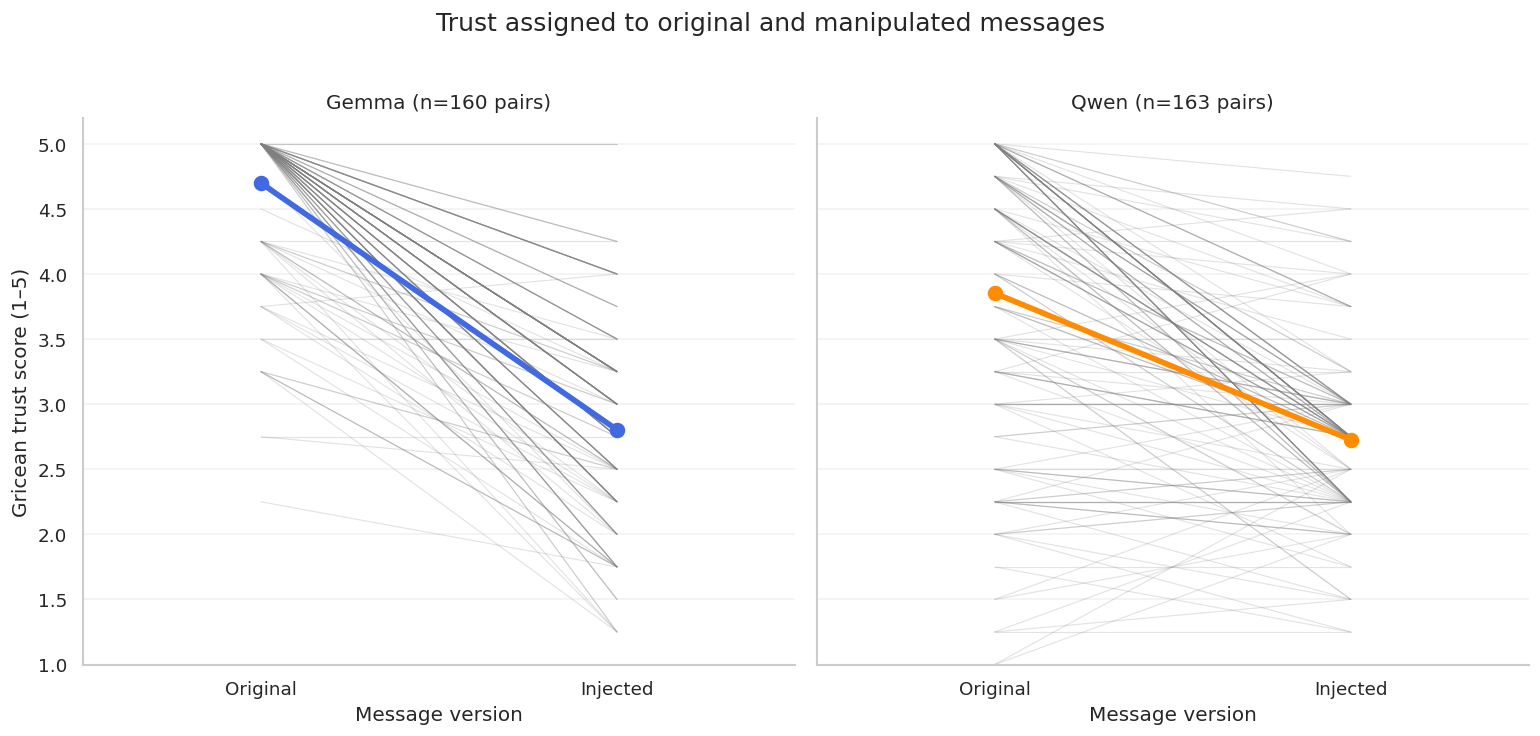

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(13, 6), sharey=True)
for ax, experiment_name in zip(axes, RUN_DIRS):
    sub = vq2_df[vq2_df["Experiment"] == experiment_name].copy()
    long = sub.melt(
        id_vars=["Task"], value_vars=["Original trust", "Injected trust"],
        var_name="Message version", value_name="Trust score",
    )
    long["Message version"] = long["Message version"].map({"Original trust": "Original", "Injected trust": "Injected"})
    long["Task line"] = long["Task"].astype(str)
    sns.lineplot(
        data=long, x="Message version", y="Trust score",
        units="Task line", estimator=None, sort=False,
        color="gray", alpha=0.22, linewidth=0.7, legend=False, ax=ax,
    )
    sns.pointplot(
        data=long, x="Message version", y="Trust score",
        errorbar=None, color=PALETTE[experiment_name],
        markers="o", linestyles="-", scale=1.25, ax=ax,
    )
    ax.set(title=f"{SHORT_NAMES[experiment_name]} (n={len(sub)} pairs)",
           xlabel="Message version", ylabel="Gricean trust score (1–5)", ylim=(1, 5.2))
fig.suptitle("Trust assigned to original and manipulated messages", y=1.02, fontsize=15)
plt.tight_layout()
save_figure(fig, "figure_06_vq2_paired_trust_drop.png")
plt.show()

I also check whether the trust reduction differs by GAIA difficulty. I use a forest-style point plot of the paired change (injected minus original). The zero line means no change; points to the left mean trust fell after manipulation.

Saved /content/results_outputs/figures/figure_07_vq2_trust_drop_by_level.png


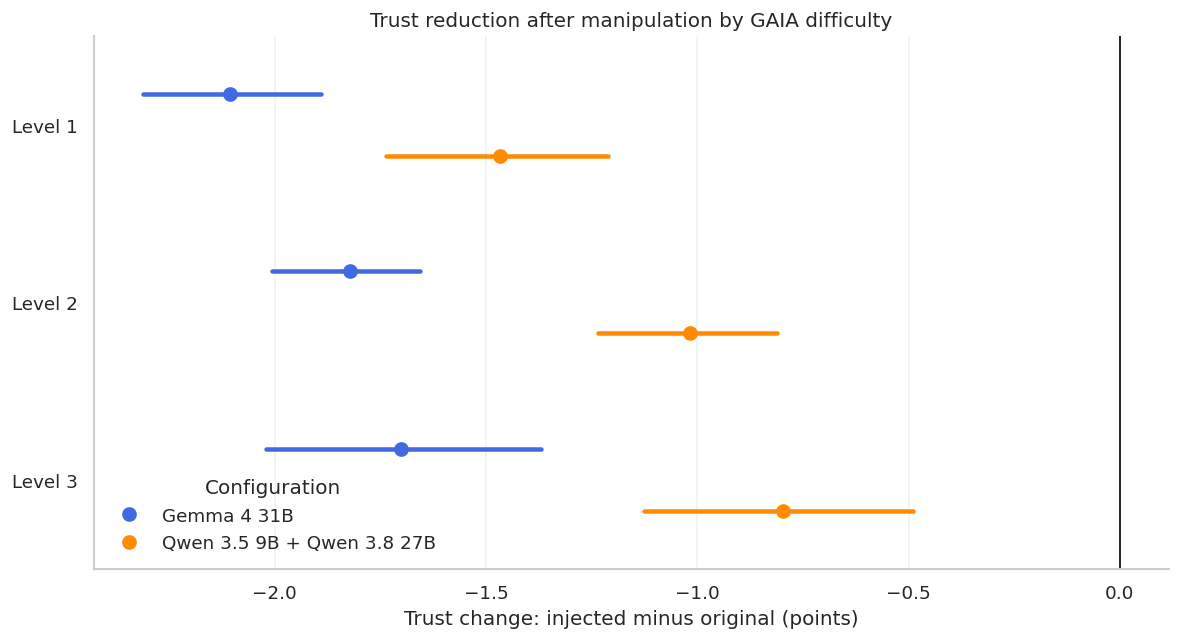

,Configuration,Injected answer correct,Pairs,Mean_original_trust,Mean_injected_trust,Mean_trust_change
0,Gemma,False,151,4.717,2.795,-1.922
1,Gemma,True,9,4.389,2.944,-1.444
2,Qwen,False,135,3.774,2.602,-1.172
3,Qwen,True,28,4.232,3.330,-0.902


,Configuration,Pairs,Original mean,Injected mean,Mean trust change,95% CI lower,95% CI upper,Trust decreased,Trust increased,Unchanged,Wilcoxon p,Holm-adjusted p,Answer incorrect · Pairs,Answer correct · Pairs,Answer incorrect · Mean_injected_trust,Answer correct · Mean_injected_trust,Answer incorrect · Mean_trust_change,Answer correct · Mean_trust_change
0,Gemma,160,4.698,2.803,-1.895,-2.009,-1.767,154,1,5,0.0,0.0,151.0,9.0,2.795,2.944,-1.922,-1.444
1,Qwen,163,3.853,2.727,-1.126,-1.279,-0.954,130,19,14,0.0,0.0,135.0,28.0,2.602,3.330,-1.172,-0.902


Saved /content/results_outputs/tables/table_14_vq2_trust_response.csv and /content/results_outputs/tables/table_14_vq2_trust_response.tex


In [26]:
vq2_df["Level label"] = vq2_df["Level"].map(lambda x: f"Level {x}")
fig, ax = plt.subplots(figsize=(10, 5.5))
sns.pointplot(
    data=vq2_df,
    x="Trust change", y="Level label", hue="Experiment",
    order=["Level 1", "Level 2", "Level 3"],
    hue_order=list(RUN_DIRS.keys()), palette=PALETTE,
    orient="h", errorbar=("ci", 95), n_boot=N_BOOT,
    dodge=0.35, markers="o", linestyles="none", ax=ax,
)
ax.axvline(0, color="black", linewidth=1)
ax.set(title="Trust reduction after manipulation by GAIA difficulty",
       xlabel="Trust change: injected minus original (points)", ylabel="")
ax.legend(title="Configuration", frameon=False)
plt.tight_layout()
save_figure(fig, "figure_07_vq2_trust_drop_by_level.png")
plt.show()

# I report separately whether the injected message's answer was still correct.
vq2_answer_table = (
    vq2_df.groupby(["Configuration", "Injected answer correct"])
    .agg(
        Pairs=("Task", "nunique"),
        Mean_original_trust=("Original trust", "mean"),
        Mean_injected_trust=("Injected trust", "mean"),
        Mean_trust_change=("Trust change", "mean"),
    )
    .reset_index()
)
display(vq2_answer_table.round(3))
answer_split = vq2_answer_table.pivot(
    index="Configuration", columns="Injected answer correct",
    values=["Pairs", "Mean_injected_trust", "Mean_trust_change"]
)
answer_split.columns = [
    f"{'Answer correct' if correct else 'Answer incorrect'} · {metric}"
    for metric, correct in answer_split.columns
]
vq2_full_table = vq2_summary.merge(answer_split.reset_index(), on="Configuration", how="left")
display(vq2_full_table.round(3))
save_table(vq2_full_table, "table_14_vq2_trust_response")

## 9. Exploratory question 1: can a bad trust judgement make the result worse?

I classify the allocator's first-message judgement using the same descriptive thresholds used in the earlier analysis:

- **False reassurance:** an incorrect message receives trust of at least 4.5.
- **False distrust:** a correct message receives trust below 3.0.
- **No clear misclassification:** all other scores, including medium trust.

I compare final-answer correctness with and without the allocator for the same task. For clean runs, I require the first Agent 1 message to be identical in both conditions. For injected runs, I require both runs to contain the same successful injected message.



In [27]:
HIGH_TRUST = 4.5
LOW_TRUST = 3.0
summary_lookup = {
    experiment: dfs[experiment].set_index(["task_id", "condition"])["correct"].to_dict()
    for experiment in RUN_DIRS
}

misallocation_rows = []
for experiment_name in RUN_DIRS:
    for scenario, off_condition, on_condition in [
        ("Clean", "baseline_off", "baseline_on"),
        ("Injected", "fork_off", "fork_on"),
    ]:
        off_data = trace_records[experiment_name][off_condition]
        on_data = trace_records[experiment_name][on_condition]
        for task_id in set(off_data) & set(on_data):
            off, on = off_data[task_id], on_data[task_id]
            if scenario == "Clean":
                if not off["messages"] or not on["messages"]:
                    continue
                if off["messages"][0]["content_hash"] != on["messages"][0]["content_hash"]:
                    continue
            else:
                inj_off, inj_on = off["injection"], on["injection"]
                if not (inj_off["eligible"] and inj_on["eligible"]):
                    continue
                if not inj_off["corrupted_hash"] or inj_off["corrupted_hash"] != inj_on["corrupted_hash"]:
                    continue
                if not off["messages"] or not on["messages"]:
                    continue
                if off["messages"][0]["content_hash"] != inj_off["corrupted_hash"]:
                    continue
                if on["messages"][0]["content_hash"] != inj_on["corrupted_hash"]:
                    continue

            if not on["messages"]:
                continue
            trust = trust_score_at(on, 0)
            if not np.isfinite(trust):
                continue
            first_correct = bool(on["messages"][0]["step_correct"])
            if (not first_correct) and trust >= HIGH_TRUST:
                decision = "False reassurance"
            elif first_correct and trust < LOW_TRUST:
                decision = "False distrust"
            else:
                decision = "No clear misclassification"

            final_off = summary_lookup[experiment_name].get((task_id, off_condition))
            final_on = summary_lookup[experiment_name].get((task_id, on_condition))
            if final_off is None or final_on is None:
                continue
            misallocation_rows.append({
                "Experiment": experiment_name,
                "Configuration": SHORT_NAMES[experiment_name],
                "Scenario": scenario,
                "Task": task_id,
                "Level": difficulty_map[task_id],
                "First message correct": first_correct,
                "Trust score": trust,
                "Decision": decision,
                "Allocator mistake": decision != "No clear misclassification",
                "Final OFF": int(final_off),
                "Final ON": int(final_on),
                "Final change (ON - OFF)": int(final_on) - int(final_off),
            })

misallocation_df = pd.DataFrame(misallocation_rows)
print("Matched first-message comparisons:", len(misallocation_df))

Matched first-message comparisons: 643


In [28]:
misallocation_table = (
    misallocation_df.groupby(["Configuration", "Scenario", "Decision"])
    .agg(
        Tasks=("Task", "nunique"),
        Mean_trust=("Trust score", "mean"),
        Final_accuracy_OFF_pct=("Final OFF", lambda x: 100 * x.mean()),
        Final_accuracy_ON_pct=("Final ON", lambda x: 100 * x.mean()),
        Final_accuracy_change_pp=("Final change (ON - OFF)", lambda x: 100 * x.mean()),
        Trust_made_result_worse=("Final change (ON - OFF)", lambda x: int((x < 0).sum())),
        Trust_made_result_better=("Final change (ON - OFF)", lambda x: int((x > 0).sum())),
    )
    .reset_index()
)
display(misallocation_table.round(2))
save_table(misallocation_table, "table_16_first_message_misallocation")

,Configuration,Scenario,Decision,Tasks,Mean_trust,Final_accuracy_OFF_pct,Final_accuracy_ON_pct,Final_accuracy_change_pp,Trust_made_result_worse,Trust_made_result_better
0,Gemma,Clean,False distrust,1,2.75,100.00,100.00,0.00,0,0
1,Gemma,Clean,False reassurance,32,4.98,15.62,21.88,6.25,1,3
2,Gemma,Clean,No clear misclassification,126,4.63,83.33,83.33,0.00,0,0
3,Gemma,Injected,False distrust,5,2.40,40.00,40.00,0.00,0,0
4,Gemma,Injected,False reassurance,1,5.00,0.00,0.00,0.00,0,0
5,Gemma,Injected,No clear misclassification,151,2.80,72.19,70.86,-1.32,6,4
6,Qwen,Clean,False distrust,3,2.50,100.00,66.67,-33.33,1,0
7,Qwen,Clean,False reassurance,12,4.71,8.33,33.33,25.00,1,4
8,Qwen,Clean,No clear misclassification,149,3.81,65.10,63.09,-2.01,10,7
9,Qwen,Injected,False distrust,13,2.65,69.23,76.92,7.69,1,2


Saved /content/results_outputs/tables/table_16_first_message_misallocation.csv and /content/results_outputs/tables/table_16_first_message_misallocation.tex


I keep the full table above, but the figure shows only tasks where the allocator made one of the two defined mistakes. I plot the paired change in final-answer correctness (trust ON minus OFF) by difficulty. This is the closest direct test of whether a poor first-message judgement coincided with a worse task outcome.

Saved /content/results_outputs/figures/figure_08_misallocation_consequences.png


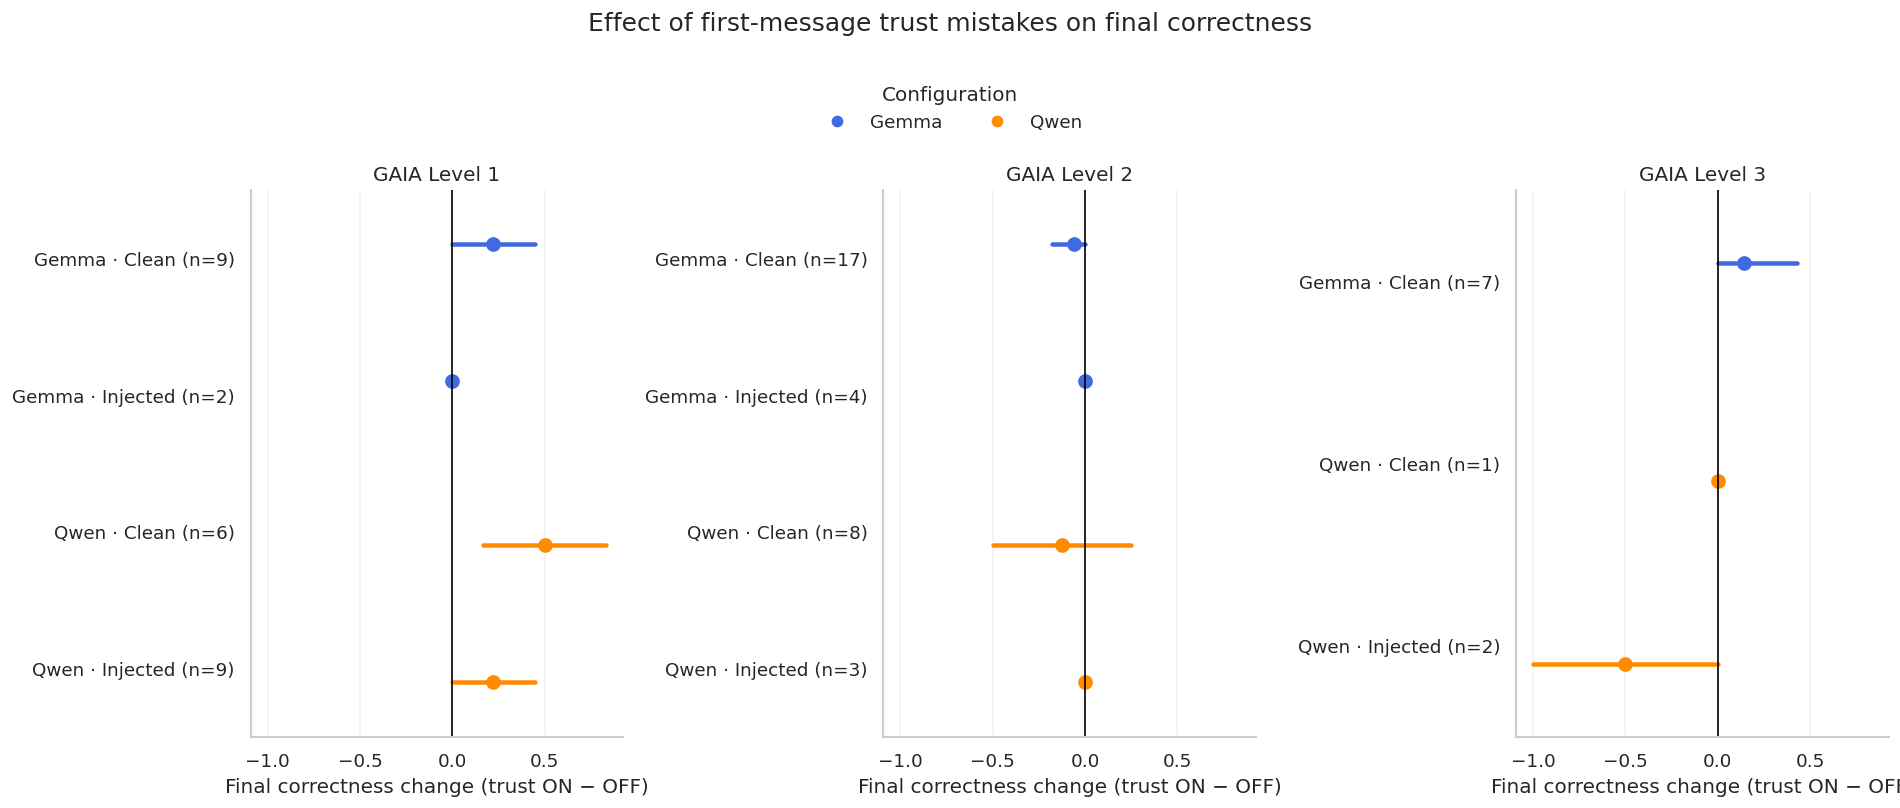

In [29]:
mistakes_only = misallocation_df[misallocation_df["Allocator mistake"]].copy()

fig, axes = plt.subplots(1, 3, figsize=(16, 6), sharex=True)
for ax, level in zip(axes, [1, 2, 3]):
    data = mistakes_only[mistakes_only["Level"] == level].copy()
    if data.empty:
        ax.set_title(f"GAIA Level {level} (no mistake cases)")
        continue

    data["Plot row"] = data["Configuration"].map({"Gemma": "Gemma", "Qwen": "Qwen"}) + " · " + data["Scenario"]
    row_order = []
    for config in ["Gemma", "Qwen"]:
        for scenario in ["Clean", "Injected"]:
            row = data[(data["Configuration"] == config) & (data["Scenario"] == scenario)]
            if len(row):
                row_order.append(f"{config} · {scenario} (n={len(row)})")
                data.loc[row.index, "Plot row"] = row_order[-1]

    sns.pointplot(
        data=data,
        x="Final change (ON - OFF)",
        y="Plot row",
        hue="Configuration",
        order=row_order,
        hue_order=["Gemma", "Qwen"],
        palette={"Gemma": "royalblue", "Qwen": "darkorange"},
        orient="h",
        errorbar=("ci", 95),
        n_boot=N_BOOT,
        dodge=0.2,
        markers="o",
        linestyles="none",
        ax=ax,
    )
    ax.axvline(0, color="black", linewidth=1)
    ax.set_title(f"GAIA Level {level}")
    ax.set_xlabel("Final correctness change (trust ON − OFF)")
    ax.set_ylabel("")
    if ax.legend_:
        ax.legend_.remove()
    ax.grid(axis="x", alpha=0.25)

handles = [
    plt.Line2D([0], [0], marker="o", color="royalblue", linestyle="", label="Gemma"),
    plt.Line2D([0], [0], marker="o", color="darkorange", linestyle="", label="Qwen"),
]
fig.legend(handles=handles, title="Configuration", frameon=False, loc="upper center", ncol=2, bbox_to_anchor=(0.5, 1.04))
fig.suptitle("Effect of first-message trust mistakes on final correctness", y=1.12, fontsize=15)
plt.tight_layout()
save_figure(fig, "figure_08_misallocation_consequences.png")
plt.show()


## 10. Exploratory question 2: does longer context weaken judgement?

I examine two separate relationships:

1. whether the trust allocator discriminates less well between correct and incorrect messages when its audit prompt is longer;
2. whether final-answer accuracy is lower on tasks where debate-agent prompts are longer.

For the first relationship, I match a trust-audit call to a trust-history entry by comparing the four maxim scores returned in the call with the four scores stored in `trust_history`.  A few records cannot be matched and are excluded from this part.

For the second relationship, I summarise each task's successful debate-agent calls. Note that difficult tasks can naturally produce longer prompts and lower accuracy, so a trend does not prove that context length caused the error.



In [30]:
context_rows = []
agent_context_rows = []
context_match_audit = []

for experiment_name in RUN_DIRS:
    for task_id, trace in trace_records[experiment_name]["baseline_on"].items():
        messages_by_index = {m["log_index"]: m for m in trace["messages"]}
        history = sorted(trace["trust_history"], key=lambda x: (x.get("step") if x.get("step") is not None else 10**9))
        calls = sorted(
            [c for c in trace["calls"] if c["call_type"] == "trust_audit" and c["status"] == "ok"],
            key=lambda x: (x.get("call_index") if x.get("call_index") is not None else 10**9),
        )
        call_scores = [c.get("maxim_scores_from_output") for c in calls]
        cursor = 0
        matched = 0
        for item in history:
            target = item.get("maxim_scores") or {}
            target = {k: float(target[k]) for k in ["quality", "quantity", "relation", "manner"] if isinstance(target.get(k), (int, float))}
            if len(target) != 4:
                continue
            found = None
            for j in range(cursor, len(calls)):
                if call_scores[j] == target:
                    found = j
                    break
            if found is None:
                continue
            call = calls[found]
            cursor = found + 1
            message = messages_by_index.get(item.get("message_index"))
            if message is None or not isinstance(call.get("prompt_tokens"), (int, float)):
                continue
            context_rows.append({
                "Experiment": experiment_name,
                "Configuration": SHORT_NAMES[experiment_name],
                "Task": task_id,
                "Level": difficulty_map[task_id],
                "Message index": item.get("message_index"),
                "Context tokens": float(call["prompt_tokens"]),
                "Trust score": float(item["trust_score"]) if isinstance(item.get("trust_score"), (int, float)) else np.nan,
                "Correct": bool(message["step_correct"]),
            })
            matched += 1

        context_match_audit.append({
            "Configuration": SHORT_NAMES[experiment_name],
            "Task": task_id,
            "Trust records": len(history),
            "Successful audit calls": len(calls),
            "Matched audit-message pairs": matched,
        })

        agent_calls = [
            c for c in trace["calls"]
            if c["call_type"] == "agent_call" and c["status"] == "ok"
            and isinstance(c.get("prompt_tokens"), (int, float))
        ]
        if agent_calls:
            prompt_lengths = [float(c["prompt_tokens"]) for c in agent_calls]
            agent_context_rows.append({
                "Experiment": experiment_name,
                "Configuration": SHORT_NAMES[experiment_name],
                "Task": task_id,
                "Level": difficulty_map[task_id],
                "Final correct": bool(trace["correct"]),
                "Mean agent prompt tokens": np.mean(prompt_lengths),
                "Maximum agent prompt tokens": np.max(prompt_lengths),
                "Agent calls": len(agent_calls),
            })

context_df = pd.DataFrame(context_rows)
agent_context_df = pd.DataFrame(agent_context_rows)
context_match_audit_df = pd.DataFrame(context_match_audit)
print("Matched trust-audit/message observations:", len(context_df))
print("Tasks with agent-call context summaries:", len(agent_context_df))
print("Total trust-history entries not matched:", int((context_match_audit_df["Trust records"] - context_match_audit_df["Matched audit-message pairs"]).clip(lower=0).sum()))

Matched trust-audit/message observations: 1966
Tasks with agent-call context summaries: 329
Total trust-history entries not matched: 4


In [31]:
# I divide context length into five groups within each configuration and GAIA level.
context_auc_rows = []
agent_accuracy_rows = []
for experiment_name in RUN_DIRS:
    for level in [1, 2, 3]:
        sub = context_df[(context_df["Experiment"] == experiment_name) & (context_df["Level"] == level)].dropna(subset=["Context tokens", "Trust score", "Correct"]).copy()
        if len(sub) >= 10:
            sub["Context quintile"] = pd.qcut(sub["Context tokens"].rank(method="first"), q=5, labels=[1, 2, 3, 4, 5])
            for q, group in sub.groupby("Context quintile", observed=True):
                auc = np.nan
                if group["Correct"].nunique() == 2:
                    auc = roc_auc_score((~group["Correct"].astype(bool)).astype(int), -group["Trust score"])
                context_auc_rows.append({
                    "Experiment": experiment_name, "Configuration": SHORT_NAMES[experiment_name],
                    "Level": level, "Quintile": int(q), "Messages": len(group),
                    "Mean prompt tokens": group["Context tokens"].mean(), "ROC-AUC": auc,
                })

        agent_sub = agent_context_df[
            (agent_context_df["Experiment"] == experiment_name)
            & (agent_context_df["Level"] == level)
        ].dropna(subset=["Mean agent prompt tokens"]).copy()
        if len(agent_sub) >= 10:
            agent_sub["Context quintile"] = pd.qcut(agent_sub["Mean agent prompt tokens"].rank(method="first"), q=5, labels=[1, 2, 3, 4, 5])
            for q, group in agent_sub.groupby("Context quintile", observed=True):
                agent_accuracy_rows.append({
                    "Experiment": experiment_name, "Configuration": SHORT_NAMES[experiment_name],
                    "Level": level, "Quintile": int(q), "Tasks": len(group),
                    "Mean prompt tokens": group["Mean agent prompt tokens"].mean(),
                    "Final accuracy (%)": 100 * group["Final correct"].mean(),
                })

context_auc_df = pd.DataFrame(context_auc_rows)
agent_accuracy_context_df = pd.DataFrame(agent_accuracy_rows)
display(context_auc_df.round(3))
display(agent_accuracy_context_df.round(2))


,Experiment,Configuration,Level,Quintile,Messages,Mean prompt tokens,ROC-AUC
0,Gemma 4 31B,Gemma,1,1,63,3398.206,0.833
1,Gemma 4 31B,Gemma,1,2,63,4961.762,0.601
2,Gemma 4 31B,Gemma,1,3,63,6712.032,0.501
3,Gemma 4 31B,Gemma,1,4,63,11329.619,0.530
4,Gemma 4 31B,Gemma,1,5,63,15543.317,0.555
5,Gemma 4 31B,Gemma,2,1,103,4937.650,0.592
6,Gemma 4 31B,Gemma,2,2,103,8021.573,0.470
7,Gemma 4 31B,Gemma,2,3,103,12075.748,0.526
8,Gemma 4 31B,Gemma,2,4,103,14798.786,0.557
9,Gemma 4 31B,Gemma,2,5,103,18609.932,0.462


,Experiment,Configuration,Level,Quintile,Tasks,Mean prompt tokens,Final accuracy (%)
0,Gemma 4 31B,Gemma,1,1,11,2830.70,100.00
1,Gemma 4 31B,Gemma,1,2,10,4077.30,90.00
2,Gemma 4 31B,Gemma,1,3,11,5868.94,81.82
3,Gemma 4 31B,Gemma,1,4,10,8422.01,60.00
4,Gemma 4 31B,Gemma,1,5,11,10974.29,90.91
5,Gemma 4 31B,Gemma,2,1,18,3672.91,83.33
6,Gemma 4 31B,Gemma,2,2,17,6086.62,88.24
7,Gemma 4 31B,Gemma,2,3,17,8583.77,58.82
8,Gemma 4 31B,Gemma,2,4,17,10729.14,76.47
9,Gemma 4 31B,Gemma,2,5,17,14582.65,35.29


Saved /content/results_outputs/figures/figure_09_context_length_by_level.png


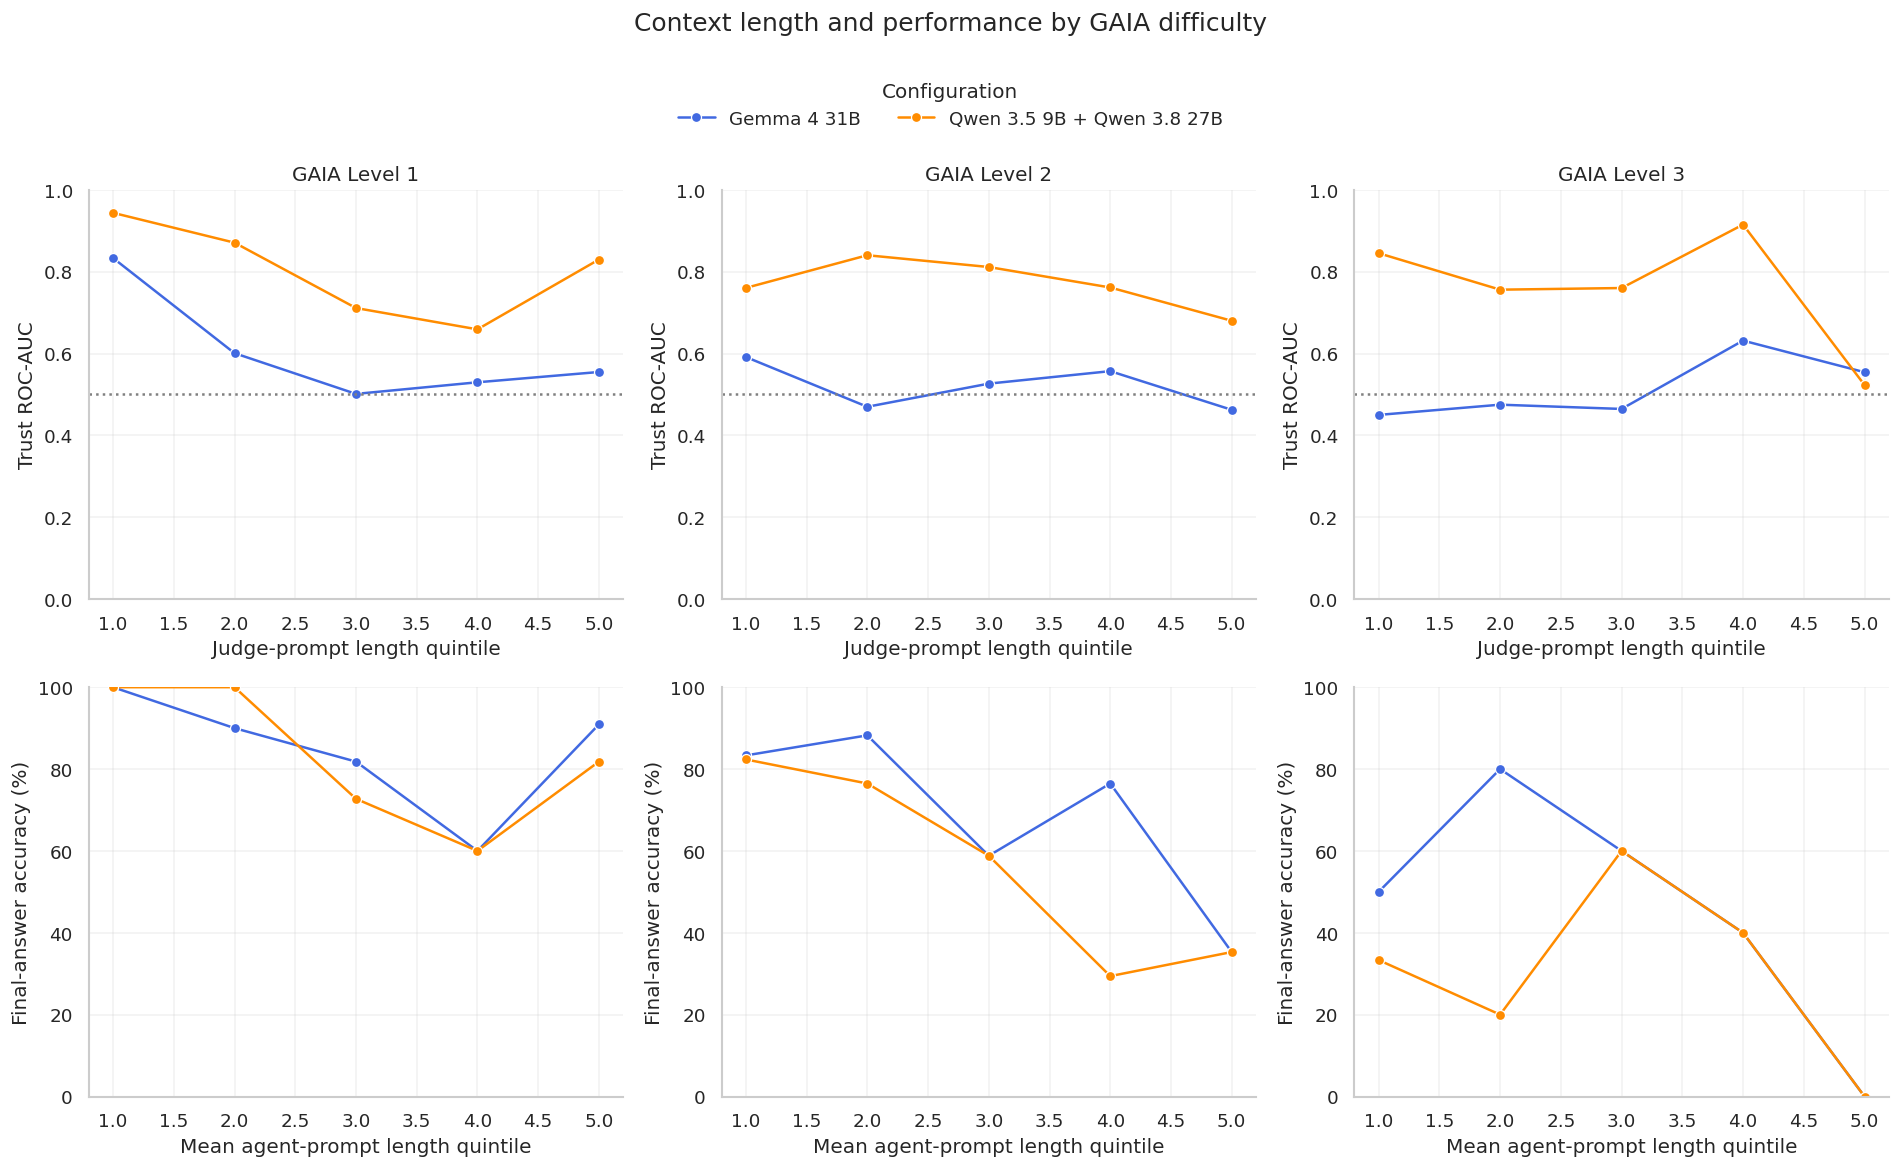

In [32]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9), sharex="row")
for col, level in enumerate([1, 2, 3]):
    judge_data = context_auc_df[context_auc_df["Level"] == level]
    sns.lineplot(
        data=judge_data, x="Quintile", y="ROC-AUC", hue="Experiment",
        hue_order=list(RUN_DIRS.keys()), palette=PALETTE,
        marker="o", errorbar=None, ax=axes[0, col],
    )
    axes[0, col].axhline(0.5, color="gray", linestyle=":")
    axes[0, col].set(title=f"GAIA Level {level}", xlabel="Judge-prompt length quintile", ylabel="Trust ROC-AUC", ylim=(0, 1))
    axes[0, col].legend_.remove() if axes[0, col].legend_ else None

    agent_data = agent_accuracy_context_df[agent_accuracy_context_df["Level"] == level]
    sns.lineplot(
        data=agent_data, x="Quintile", y="Final accuracy (%)", hue="Experiment",
        hue_order=list(RUN_DIRS.keys()), palette=PALETTE,
        marker="o", errorbar=None, ax=axes[1, col],
    )
    axes[1, col].set(xlabel="Mean agent-prompt length quintile", ylabel="Final-answer accuracy (%)", ylim=(0, 100))
    axes[1, col].legend_.remove() if axes[1, col].legend_ else None

handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, title="Configuration", frameon=False, loc="upper center", ncol=2, bbox_to_anchor=(0.5, 1.03))
fig.suptitle("Context length and performance by GAIA difficulty", y=1.08, fontsize=15)
plt.tight_layout()
save_figure(fig, "figure_09_context_length_by_level.png")
plt.show()

## 11. Exploratory question 3: what does trust allocation cost?

I count prompt and completion tokens from successful recorded LLM calls. I separate `trust_audit` calls from `agent_call` calls, but I also report total usage. The total already includes the allocator calls, so I do not add them a second time.

I also sum `elapsed_seconds` across successful calls. This is summed model-call time, not wall-clock time for the complete experiment.

In [33]:
token_rows = []
for experiment_name in RUN_DIRS:
    for condition in CONDITIONS:
        for task_id, trace in trace_records[experiment_name][condition].items():
            calls = trace["calls"]
            successful = [c for c in calls if c.get("status") == "ok"]
            def sum_usage(call_type, field):
                return sum(float(c.get(field) or 0) for c in successful if c.get("call_type") == call_type)
            total_prompt = sum(float(c.get("prompt_tokens") or 0) for c in successful)
            total_completion = sum(float(c.get("completion_tokens") or 0) for c in successful)
            audit_tokens = sum_usage("trust_audit", "prompt_tokens") + sum_usage("trust_audit", "completion_tokens")
            agent_tokens = sum_usage("agent_call", "prompt_tokens") + sum_usage("agent_call", "completion_tokens")
            token_rows.append({
                "Experiment": experiment_name,
                "Configuration": SHORT_NAMES[experiment_name],
                "Task": task_id,
                "Level": difficulty_map[task_id],
                "Condition": condition,
                "Prompt tokens": total_prompt,
                "Completion tokens": total_completion,
                "Total tokens": total_prompt + total_completion,
                "Trust-audit tokens": audit_tokens,
                "Agent tokens": agent_tokens,
                "Trust-audit calls": sum(c.get("call_type") == "trust_audit" and c.get("status") == "ok" for c in calls),
                "Successful calls": len(successful),
                "Total calls": len(calls),
                "Failed calls": sum(c.get("status") != "ok" for c in calls),
                # Failed calls may still consume compute time, so I include any recorded duration.
                "LLM seconds": sum(
                    float(c.get("elapsed_seconds") or 0)
                    for c in calls
                    if isinstance(c.get("elapsed_seconds"), (int, float))
                ),
            })
token_df = pd.DataFrame(token_rows)

cost_summary = (
    token_df.groupby(["Configuration", "Condition"])
    .agg(
        Tasks=("Task", "nunique"),
        Mean_total_tokens=("Total tokens", "mean"),
        Mean_trust_audit_tokens=("Trust-audit tokens", "mean"),
        Mean_agent_tokens=("Agent tokens", "mean"),
        Mean_LLM_minutes=("LLM seconds", lambda x: x.mean() / 60),
        Mean_calls=("Total calls", "mean"),
        Tasks_with_failed_calls=("Failed calls", lambda x: int((x > 0).sum())),
    )
    .reset_index()
)
display(cost_summary.round(1))
save_table(cost_summary, "table_19_cost_by_condition")

,Configuration,Condition,Tasks,Mean_total_tokens,Mean_trust_audit_tokens,Mean_agent_tokens,Mean_LLM_minutes,Mean_calls,Tasks_with_failed_calls
0,Gemma,baseline_off,165,256362.0,0.0,256362.0,4.9,23.1,23
1,Gemma,baseline_on,165,337282.4,79916.4,257366.0,6.5,28.1,21
2,Gemma,fork_off,165,277021.9,0.0,277021.9,5.1,23.9,21
3,Gemma,fork_on,165,350196.3,82143.4,268052.9,7.7,28.6,21
4,Qwen,baseline_off,165,296729.1,0.0,296729.1,4.7,25.3,19
5,Qwen,baseline_on,165,392131.4,98962.8,293168.6,10.8,30.1,18
6,Qwen,fork_off,165,282784.3,0.0,282784.3,4.3,25.2,17
7,Qwen,fork_on,165,369319.0,99397.5,269921.5,10.5,29.5,18


Saved /content/results_outputs/tables/table_19_cost_by_condition.csv and /content/results_outputs/tables/table_19_cost_by_condition.tex


I compare trust ON and OFF within the same task, separately for clean and injected runs. The figure shows percentage token overhead by GAIA level. I also keep the absolute number of additional tokens and the change in summed LLM-call time in the table, because percentages alone can hide the size of the cost.

In [34]:
cost_effect_rows = []
for experiment_name in RUN_DIRS:
    sub = token_df[token_df["Experiment"] == experiment_name]
    for scenario, off_condition, on_condition in [
        ("Clean", "baseline_off", "baseline_on"),
        ("Injected", "fork_off", "fork_on"),
    ]:
        wide = sub.pivot(index=["Task", "Level"], columns="Condition", values=["Total tokens", "LLM seconds"])
        wide = wide.dropna(subset=[("Total tokens", off_condition), ("Total tokens", on_condition)])
        for (task_id, level), row in wide.iterrows():
            off_tokens = row[("Total tokens", off_condition)]
            on_tokens = row[("Total tokens", on_condition)]
            off_seconds = row[("LLM seconds", off_condition)]
            on_seconds = row[("LLM seconds", on_condition)]
            cost_effect_rows.append({
                "Experiment": experiment_name,
                "Configuration": SHORT_NAMES[experiment_name],
                "Scenario": scenario,
                "Task": task_id,
                "Level": int(level),
                "Additional tokens": on_tokens - off_tokens,
                "Token overhead (%)": 100 * (on_tokens - off_tokens) / off_tokens if off_tokens else np.nan,
                "Additional LLM minutes": (on_seconds - off_seconds) / 60,
            })
cost_effect_df = pd.DataFrame(cost_effect_rows)

cost_effect_summary = (
    cost_effect_df.groupby(["Configuration", "Experiment", "Scenario", "Level"])
    .agg(
        Tasks=("Task", "nunique"),
        Additional_tokens=("Additional tokens", "mean"),
        Token_overhead_pct=("Token overhead (%)", "mean"),
        Additional_LLM_minutes=("Additional LLM minutes", "mean"),
    )
    .reset_index()
)
ci_rows = []
for _, row in cost_effect_summary.iterrows():
    group = cost_effect_df[
        (cost_effect_df["Experiment"] == row["Experiment"])
        & (cost_effect_df["Scenario"] == row["Scenario"])
        & (cost_effect_df["Level"] == row["Level"])
    ]
    lo, hi = bootstrap_mean_ci(group["Token overhead (%)"].dropna().to_numpy())
    ci_rows.append({"Experiment": row["Experiment"], "Scenario": row["Scenario"], "Level": row["Level"], "CI lower": lo, "CI upper": hi})
cost_effect_summary = cost_effect_summary.merge(pd.DataFrame(ci_rows), on=["Experiment", "Scenario", "Level"])
display(cost_effect_summary.round(2))
save_table(cost_effect_summary, "table_20_incremental_cost_by_level")

,Configuration,Experiment,Scenario,Level,Tasks,Additional_tokens,Token_overhead_pct,Additional_LLM_minutes,CI lower,CI upper
0,Gemma,Gemma 4 31B,Clean,1,53,54327.91,83.11,1.03,60.69,112.35
1,Gemma,Gemma 4 31B,Clean,2,86,82024.21,59.63,1.92,47.19,73.01
2,Gemma,Gemma 4 31B,Clean,3,26,131477.04,63.69,1.16,34.56,99.54
3,Gemma,Gemma 4 31B,Injected,1,53,73348.96,79.13,5.32,60.38,100.58
4,Gemma,Gemma 4 31B,Injected,2,86,70822.13,60.97,0.66,47.78,74.35
5,Gemma,Gemma 4 31B,Injected,3,26,80598.96,32.49,3.63,18.72,45.91
6,Qwen,Qwen 3.5 9B + Qwen 3.8 27B,Clean,1,53,108394.55,75.49,6.16,56.57,94.82
7,Qwen,Qwen 3.5 9B + Qwen 3.8 27B,Clean,2,86,77144.02,49.47,5.67,35.91,63.46
8,Qwen,Qwen 3.5 9B + Qwen 3.8 27B,Clean,3,26,129310.88,37.61,7.47,21.15,55.30
9,Qwen,Qwen 3.5 9B + Qwen 3.8 27B,Injected,1,53,84625.98,83.99,6.09,64.47,105.07


Saved /content/results_outputs/figures/figure_10_token_overhead_by_level.png


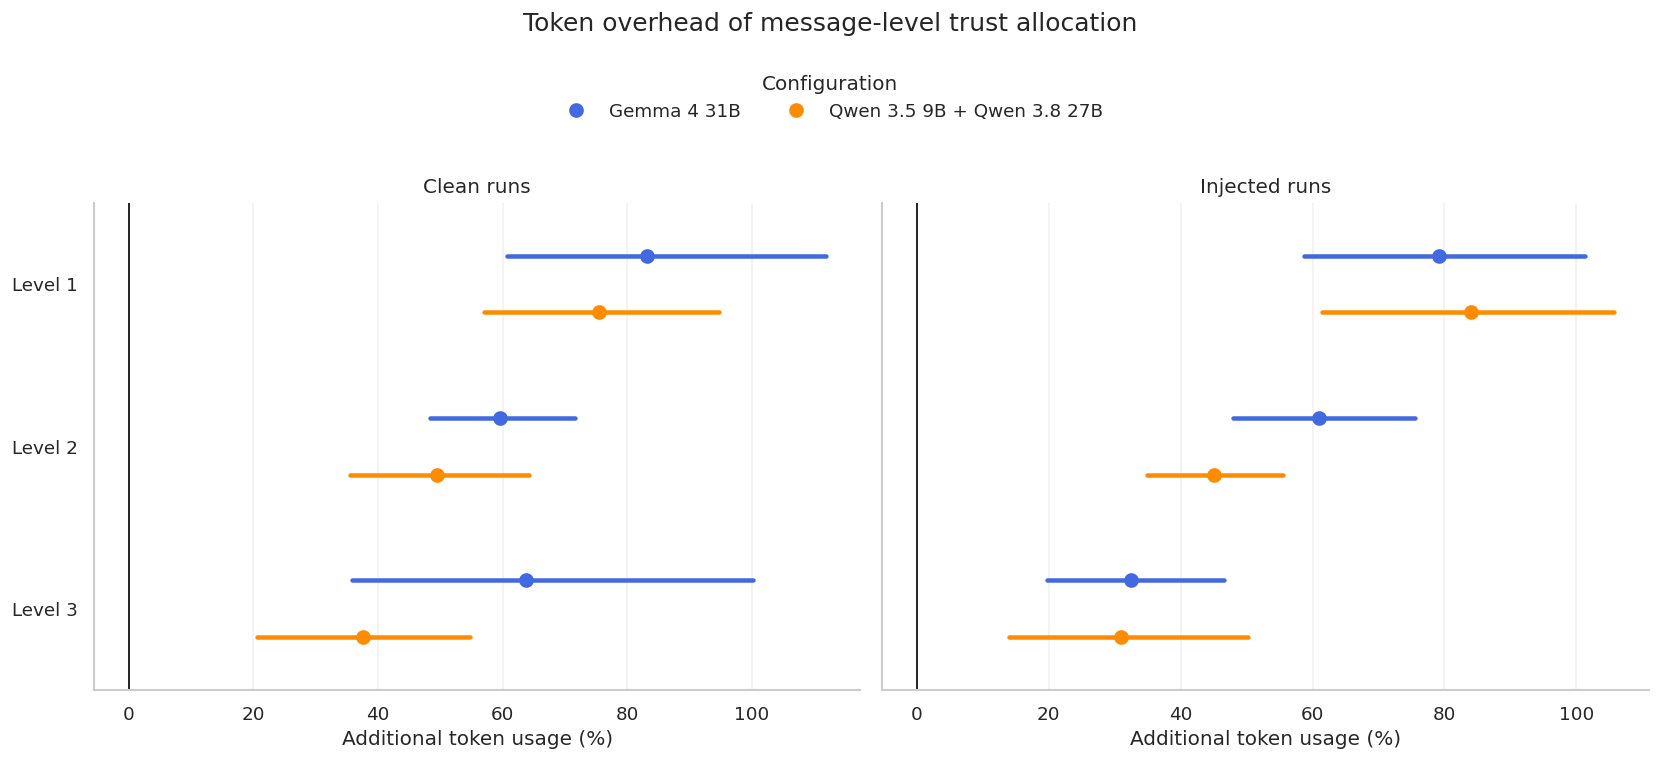

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), sharey=True)
for ax, scenario in zip(axes, ["Clean", "Injected"]):
    data = cost_effect_df[cost_effect_df["Scenario"] == scenario].copy()
    data["Level label"] = data["Level"].map(lambda x: f"Level {x}")
    sns.pointplot(
        data=data, x="Token overhead (%)", y="Level label", hue="Experiment",
        order=["Level 1", "Level 2", "Level 3"], hue_order=list(RUN_DIRS.keys()),
        palette=PALETTE, orient="h", errorbar=("ci", 95), n_boot=N_BOOT,
        dodge=0.35, markers="o", linestyles="none", ax=ax,
    )
    ax.axvline(0, color="black", linewidth=1)
    ax.set(title=f"{scenario} runs", xlabel="Additional token usage (%)", ylabel="")
    ax.legend_.remove() if ax.legend_ else None
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, title="Configuration", frameon=False, loc="upper center", ncol=2, bbox_to_anchor=(0.5, 1.08))
fig.suptitle("Token overhead of message-level trust allocation", y=1.15, fontsize=15)
plt.tight_layout()
save_figure(fig, "figure_10_token_overhead_by_level.png")
plt.show()